# Reranker-Only Pipeline: Logged MIND Slates -> Rule Baselines and RR4 Reranker -> Final K

This notebook evaluates the **reranking stage on its own**. It does not require any other
notebook to be executed first.

1. **Candidates**: the exact slates MIND logged. Every impression keeps the articles that were
   actually shown, so no candidate generator is involved and every candidate has a click label.
2. **Rule baselines**: causal popularity (smoothed prior article CTR) and content similarity
   (entity cosine to the user's causal click profile). Neither has trainable parameters.
3. **Reranker**: trains the `RR_4` `+metadata` attention reranker inside this notebook (or loads
   its checkpoint) with the same data, preprocessing, loss and training loop as stage 3 of
   `RR_4_branch_interaction.ipynb`.
4. **Evaluation**: every model reorders the target-split slates; the ranked lists are evaluated
   at each cutoff in `K_VALUES`, overall and by user history.
5. **Feature importance**: grouped permutation importance and SHAP values show how much RR4's
   ranking depends on each group of tabular features.
6. **Diagnostics**: training convergence, the validation-to-test gap, where RR4 wins and loses,
   how it ranks new and older articles, and which clicks it misses.

Saved artifacts are the reranker checkpoint and preprocessor, one score file per model, and the
metric tables.

**Labels are complete here.** Unlike the end-to-end pipelines in `2_CG_RR_E2E`, every candidate
was shown, so a non-clicked candidate is a real negative. These metrics measure how well each
model orders a slate. They are an upper bound on reranking quality, not an estimate of the full
system, where the reranker also sees generated articles that were never shown.

## 0. Configure

**This is the only cell you need to edit.** The defaults run the full experiment on the whole
dataset. After editing, run the whole notebook with **Runtime > Run all**.

In [ ]:
# ---- Where to run ----------------------------------------------------------------------------
# "colab" = Google Colab with Google Drive, "local" = this computer, "auto" = detect automatically.
RUN_ENV = "auto"

# ---- Paths -------------------------------------------------------------------------------------
# Project folder: the folder holding the code (this repository).
# On Colab, add a shortcut to the shared `submission` folder in My Drive first. The code is its
# `4.Code` folder; it is also found when the shortcut sits one folder deeper in My Drive.
COLAB_PROJECT_PATH = "/content/drive/MyDrive/submission/4.Code"
LOCAL_PROJECT_PATH = None  # None = the repository this notebook is opened from

# Data path: the prepared data, set separately for Colab and local runs. It must contain
# 3_Representations/artifacts/ and 4_Feature_Engineering/artifacts/prequential-all/.
# Metrics are written to <data path>/results/.
COLAB_DATA_PATH = "/content/drive/MyDrive/submission/2.Feature_Engineering"
LOCAL_DATA_PATH = (
    "/Users/numkoos/Downloads/v3-mindsmall"  # used locally; None = the project folder
)

# ---- Reranker model --------------------------------------------------------------------------
# False: load the trained RR4 reranker (model.pt and preprocessor.joblib) from the load path.
#        No training; takes seconds. Stops with an error if the files are not there.
# True:  train a new RR4 reranker on the training split (about 10 minutes on a GPU) and save it
#        to the save path. The load path is not touched.
TRAIN_RERANKER = False

COLAB_LOAD_MODEL_PATH = "/content/drive/MyDrive/submission/3.Model_Artifacts/reranker"
COLAB_SAVE_MODEL_PATH = "/content/drive/MyDrive/submission/3.Model_Artifacts/Train_Reranker"
# Local runs; None = <data path>/5_Models/5_03_Pipeline_Evaluation/artifacts/reranker_logged_slates/reranker
LOCAL_LOAD_MODEL_PATH = None
LOCAL_SAVE_MODEL_PATH = None

# ---- Experiment --------------------------------------------------------------------------------
# Split to evaluate: "test" for the final results, or "validation".
TARGET_SPLIT = "test"

# Training impressions for the reranker (only used when TRAIN_RERANKER = True).
# None = the whole training set (default).
# A number, e.g. 5_000, trains on a random sample instead for a quicker run.
TRAIN_IMPRESSIONS = None


## 1.1 Load Packages

In [97]:
import json
import os
import random
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from torch import nn

## 1.2 Set Up Paths

The run mode, project folder, data path and model path all come from the **Configure** cell
(section 0). On Colab the notebook mounts Google Drive and finds the shared project folder at
`COLAB_PROJECT_PATH`, or one folder down in My Drive. The data folders are checked up front, so a
wrong `DATA_PATH` fails here with the missing folder named.

In [98]:
# Run mode and paths come from the Configure cell (section 0)
ENVIRONMENT = RUN_ENV.lower()
if ENVIRONMENT == "auto":
    ENVIRONMENT = "colab" if "google.colab" in sys.modules else "local"
if ENVIRONMENT not in {"colab", "local"}:
    raise ValueError('RUN_ENV must be "auto", "colab" or "local"')

if ENVIRONMENT == "colab":
    from google.colab import drive

    drive.mount("/content/drive")
    requested = Path(COLAB_PROJECT_PATH)
    CODE_ROOT = next(
        (
            p
            for p in [
                requested,
                *Path("/content/drive/MyDrive").glob(f"*/{requested.name}"),
            ]
            if (p / "run_all.py").is_file()
        ),
        None,
    )
    if CODE_ROOT is None:
        raise FileNotFoundError(
            f"Could not find the project folder at {requested}. In Google Drive, right-click the shared "
            "folder > Organise > Add shortcut > My Drive (or fix COLAB_PROJECT_PATH), then rerun."
        )
elif LOCAL_PROJECT_PATH:
    CODE_ROOT = Path(LOCAL_PROJECT_PATH).expanduser().resolve()
else:
    CODE_ROOT = next(
        p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_all.py").is_file()
    )
ROOT = CODE_ROOT
DATA_PATH = COLAB_DATA_PATH if ENVIRONMENT == "colab" else LOCAL_DATA_PATH
DATA_ROOT = (
    Path(DATA_PATH or os.environ.get("NEWSREC_DATA_ROOT") or CODE_ROOT)
    .expanduser()
    .resolve()
)

REQUIRED_DATA = [
    "3_Representations/artifacts",
    "4_Feature_Engineering/artifacts/prequential-all",
]
missing_data = [
    str(DATA_ROOT / sub) for sub in REQUIRED_DATA if not (DATA_ROOT / sub).exists()
]
if missing_data:
    raise FileNotFoundError(
        f"{ENVIRONMENT.upper()}_DATA_PATH is missing these folders:\n"
        + "\n".join(missing_data)
    )

REPRESENTATIONS = DATA_ROOT / "3_Representations" / "artifacts"
RUN = DATA_ROOT / "4_Feature_Engineering" / "artifacts" / "prequential-all"
OUTPUT_DIR = DATA_ROOT / "5_Models" / "5_03_Pipeline_Evaluation" / "artifacts"
MODEL_DIR = OUTPUT_DIR / "reranker_logged_slates"
DEFAULT_RR4_DIR = MODEL_DIR / "reranker"


def model_folder(colab_path, local_path):
    chosen = colab_path if ENVIRONMENT == "colab" else local_path
    return Path(chosen).expanduser().resolve() if chosen else DEFAULT_RR4_DIR


RR4_LOAD_DIR = model_folder(COLAB_LOAD_MODEL_PATH, LOCAL_LOAD_MODEL_PATH)  # TRAIN_RERANKER = False
RR4_SAVE_DIR = model_folder(COLAB_SAVE_MODEL_PATH, LOCAL_SAVE_MODEL_PATH)  # TRAIN_RERANKER = True
SCORE_DIR = MODEL_DIR / "scores"
RESULTS = DATA_ROOT / "results"

sys.path.insert(0, str(ROOT / "5_Models" / "5_02_Reranking"))
from rr_evaluation import RerankingEvaluator, compare_results, write_scores

# Check the reranker files now, before any data is loaded
if not TRAIN_RERANKER:
    missing_model = [n for n in ("model.pt", "preprocessor.joblib") if not (RR4_LOAD_DIR / n).is_file()]
    if missing_model:
        found = (
            sorted(p.name for p in RR4_LOAD_DIR.iterdir())
            if RR4_LOAD_DIR.is_dir()
            else "the folder does not exist"
        )
        raise FileNotFoundError(
            f"No trained reranker at {RR4_LOAD_DIR}: missing {', '.join(missing_model)} "
            f"(found: {found}).\nFix the load path in the Configure cell, or set TRAIN_RERANKER = True "
            "to train a new model (about 10 minutes on a GPU)."
        )

for path in (OUTPUT_DIR, MODEL_DIR, SCORE_DIR, RESULTS):
    path.mkdir(parents=True, exist_ok=True)

print("Run mode:", ENVIRONMENT)
print("Repository:", ROOT)
print("Data path:", DATA_ROOT)
if TRAIN_RERANKER:
    print("Reranker: train a new model and save it to", RR4_SAVE_DIR)
else:
    print("Reranker: load the trained model from", RR4_LOAD_DIR)

Run mode: local
Repository: /Users/numkoos/Downloads/BT4222-Group-6-
Data path: /Users/numkoos/Downloads/v3-mindsmall
Reranker: train a new model and save it to /Users/numkoos/Downloads/v3-mindsmall/5_Models/5_03_Pipeline_Evaluation/artifacts/reranker_logged_slates/reranker


## 1.3 Configuration

The RR4 settings are copied from `RR_4_branch_interaction.ipynb`:

- **Architecture**: `+metadata` (tabular + text + metadata + user self-attention).
- **Preprocessor**: fitted on the fit part of a `PREPROCESSOR_IMPRESSIONS = 10_000` training
  sample, exactly as RR_4 fitted it in its section 3.5 and reused it in stage 3.
- **Final training** (when `TRAIN_RERANKER = True`): every training impression
  (`TRAIN_IMPRESSIONS = None` in the Configure cell), slates capped at 100 candidates,
  `softmax+lambda_ndcg`, up to 20 epochs. Early stopping follows the MIND protocol (Wu et al.,
  2020): after every epoch the model is scored on the validation day (13 Nov), the epoch with the
  best validation nDCG@10 is kept, and training stops after 3 epochs without improvement. The test
  day (14 Nov) is only scored once, at the end.

`TRAIN_RERANKER` (Configure cell) chooses between loading and training. `False` loads `model.pt`
and `preprocessor.joblib` from the load path and stops with an error if they are missing or were
built for different features or a different architecture. `True` trains a new model and saves it
to the save path, leaving the load path untouched.

In [99]:
TRAIN_SPLIT = "train"
K_VALUES = (5, 10, 30)
K = max(K_VALUES)
SEED = 4222

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Rule baselines
POPULARITY_MODEL = "popularity_smoothed_prior_article_ctr"
CONTENT_MODEL = "content_entity_cosine"

# RR4 reranker settings (RR_4_branch_interaction.ipynb)
CONFIG = {
    "tabular": True,
    "text": True,
    "metadata": True,
    "title_encoder": False,
    "user_encoder": True,
    "position": False,
    "candidate_pooling": False,
    "short_term": False,
}
MODEL_DIM = 64
ATTENTION_HEADS = 2
ATTENTION_DROPOUT = 0.10
HIDDEN_DIMS = (256, 64)
DROPOUT = 0.20
NDCG_K = 10
LOSS_NAME = "softmax+lambda_ndcg"
HISTORY_CAP = 30
SHORT_TERM_CAP = 10
MAX_CANDIDATES = 100
HOLDOUT_FRACTION = 0.10  # only splits the preprocessor sample, exactly as RR_4 fitted its preprocessor
PREPROCESSOR_IMPRESSIONS = (
    10_000  # RR_4 TRAIN_IMPRESSIONS: sample the preprocessor is fitted on
)
FULL_TRAIN_IMPRESSIONS = (
    TRAIN_IMPRESSIONS  # set in the Configure cell; None = every training impression
)
EPOCHS = 20
PATIENCE = 3
BATCH_IMPRESSIONS = 64
SCORING_BATCH_ROWS = 2048
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
RR4_MODEL = "attention_reranker"

TRAINING_SETTINGS = {
    "loss": LOSS_NAME,
    "max_candidates": MAX_CANDIDATES,
    "early_stopping": "validation_ndcg_at_10",
    "preprocessor_impressions": PREPROCESSOR_IMPRESSIONS,
    "full_train_impressions": FULL_TRAIN_IMPRESSIONS,
    "epochs": EPOCHS,
    "patience": PATIENCE,
    "batch_impressions": BATCH_IMPRESSIONS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "history_cap": HISTORY_CAP,
    "seed": SEED,
}
MODEL_NAMES = [POPULARITY_MODEL, CONTENT_MODEL, RR4_MODEL]
MODEL_LABELS = {
    POPULARITY_MODEL: "Popularity (rule)",
    CONTENT_MODEL: "Content similarity (rule)",
    RR4_MODEL: "RR4 attention reranker",
}

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)

if TARGET_SPLIT not in {"validation", "test"}:
    raise ValueError("TARGET_SPLIT must be validation or test")

schema = json.loads((RUN / "feature_schema.json").read_text())
FEATURES = schema["model_columns"]
CATEGORICAL = [
    name for name in schema.get("categorical_columns", []) if name in FEATURES
]
NUMERIC = [name for name in FEATURES if name not in CATEGORICAL]


def load_rr4_checkpoint(folder):
    """Read a trained RR4 checkpoint and check it fits this notebook's features and architecture."""
    missing = [name for name in ("model.pt", "preprocessor.joblib") if not (folder / name).is_file()]
    if missing:
        raise FileNotFoundError(
            f"TRAIN_RERANKER = False, but {folder} has no {' or '.join(missing)}. Put the trained "
            "model.pt and preprocessor.joblib there, fix the load path in the Configure cell, or set "
            "TRAIN_RERANKER = True to train a new model."
        )
    meta = torch.load(folder / "model.pt", map_location="cpu", weights_only=False)
    if meta.get("features") != FEATURES:
        raise ValueError(f"The model in {folder} was trained on a different feature schema")
    if meta.get("config") != CONFIG:
        raise ValueError(f"The model in {folder} has a different architecture: {meta.get('config')}")
    different = sorted(
        key
        for key in TRAINING_SETTINGS
        if (meta.get("training") or {}).get(key, "missing") != TRAINING_SETTINGS[key]
    )
    if different:
        print(f"Note: the loaded model was trained with different settings for: {', '.join(different)}")
    return meta


if TRAIN_RERANKER:
    RR4_CHECKPOINT_META = None
    RR4_DIR = RR4_SAVE_DIR
    RR4_DIR.mkdir(parents=True, exist_ok=True)
else:
    RR4_CHECKPOINT_META = load_rr4_checkpoint(RR4_LOAD_DIR)
    RR4_DIR = RR4_LOAD_DIR
RR4_LOADED = not TRAIN_RERANKER
RR4_CHECKPOINT_PATH = RR4_DIR / "model.pt"
PREPROCESSOR_PATH = RR4_DIR / "preprocessor.joblib"

print("Target split:", TARGET_SPLIT)
print("Reported K values:", K_VALUES)
print("Device:", DEVICE)
print(
    f"Tabular features: {len(FEATURES)} ({len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical)"
)
print("Models:", MODEL_NAMES)
print(("RR4: loading " if RR4_LOADED else "RR4: training; will save to ") + str(RR4_CHECKPOINT_PATH))

Target split: test
Reported K values: (5, 10, 30)
Device: mps
Tabular features: 50 (48 numeric, 2 categorical)
Models: ['popularity_smoothed_prior_article_ctr', 'content_entity_cosine', 'attention_reranker']
RR4: training; will save to /Users/numkoos/Downloads/v3-mindsmall/5_Models/5_03_Pipeline_Evaluation/artifacts/reranker_logged_slates/reranker/model.pt


## 1.4 Check the Inputs

Every input is checked before anything heavy runs, so a missing Drive upload fails immediately
with its path.

In [100]:
def folder_size(path):
    if path.is_file():
        return path.stat().st_size
    return sum(item.stat().st_size for item in path.rglob("*") if item.is_file())


REQUIRED_INPUTS = {
    "rr_evaluation.py": ROOT / "5_Models" / "5_02_Reranking" / "rr_evaluation.py",
    "feature schema": RUN / "feature_schema.json",
    **{
        f"ranking features ({s})": RUN / f"ranking_features_{s}"
        for s in (TRAIN_SPLIT, TARGET_SPLIT)
    },
    **{f"labels ({s})": RUN / f"labels_{s}" for s in (TRAIN_SPLIT, TARGET_SPLIT)},
    **{
        f"request profiles ({s})": RUN / f"request_profiles_{s}"
        for s in (TRAIN_SPLIT, TARGET_SPLIT)
    },
    "article index": REPRESENTATIONS / "article_index.parquet",
    "text vectors": REPRESENTATIONS / "text64.npy",
    "entity vectors": REPRESENTATIONS / "article_entity100.npy",
}
manifest = pd.DataFrame(
    [
        {
            "input": name,
            "exists": path.exists(),
            "size_mb": round(folder_size(path) / 1e6, 1) if path.exists() else None,
            "path": str(path),
        }
        for name, path in REQUIRED_INPUTS.items()
    ]
)
display(manifest)
missing_inputs = manifest.loc[~manifest["exists"], "path"].tolist()
if missing_inputs:
    raise FileNotFoundError("Missing inputs:\n" + "\n".join(missing_inputs))

,input,exists,size_mb,path
0,rr_evaluation.py,True,0.0,/Users/numkoos/Downloads/BT4222-Group-6-/5_Mod...
1,feature schema,True,0.0,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
2,ranking features (train),True,170.4,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
3,ranking features (test),True,62.9,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
4,labels (train),True,5.1,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
5,labels (test),True,1.8,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
6,request profiles (train),True,12.5,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
7,request profiles (test),True,4.7,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
8,article index,True,17.3,/Users/numkoos/Downloads/v3-mindsmall/3_Repres...
9,text vectors,True,13.1,/Users/numkoos/Downloads/v3-mindsmall/3_Repres...


# 2. Load and Inspect the Logged Slates

## 2.1 Logged Slates

One row per (impression, shown article). The ranking features and labels must hold exactly the
same pairs. The training split is included for reference: feature engineering already sampled
its negatives, so its slates are smaller than the complete logged slates of validation and test.

In [101]:
def scan_split(split):
    features = pl.scan_parquet(RUN / f"ranking_features_{split}" / "*.parquet")
    labels = pl.scan_parquet(RUN / f"labels_{split}" / "*.parquet")
    return features, labels


slate_summary, slate_sizes = [], {}
for split in (TRAIN_SPLIT, TARGET_SPLIT):
    features, labels = scan_split(split)
    keys = features.select(
        "impression_uid", "news_code", "user_code", "timestamp"
    ).collect()
    label_frame = labels.select("impression_uid", "news_code", "clicked").collect()
    joined = keys.join(label_frame, on=["impression_uid", "news_code"], how="inner")
    if not (joined.height == keys.height == label_frame.height):
        raise ValueError(
            f"{split}: ranking features and labels disagree on the logged pairs"
        )

    per_impression = joined.group_by("impression_uid").agg(
        pl.len().alias("slate_size"), pl.col("clicked").sum().alias("clicks")
    )
    slate_sizes[split] = per_impression
    slate_summary.append(
        {
            "split": split,
            "rows": joined.height,
            "impressions": per_impression.height,
            "users": joined["user_code"].n_unique(),
            "articles": joined["news_code"].n_unique(),
            "clicks": int(joined["clicked"].sum()),
            "row_ctr": joined["clicked"].mean(),
            "impressions_without_click": int((per_impression["clicks"] == 0).sum()),
            "first_timestamp": joined["timestamp"].min(),
            "last_timestamp": joined["timestamp"].max(),
        }
    )

display(pl.DataFrame(slate_summary))

split,rows,impressions,users,articles,clicks,row_ctr,impressions_without_click,first_timestamp,last_timestamp
str,i64,i64,i64,i64,i64,f64,i64,datetime[μs],datetime[μs]
"""train""",3389342,95071,40148,13536,141558,0.041766,0,2019-11-09 00:00:19,2019-11-12 23:59:25
"""test""",1222429,30270,20179,6144,46825,0.038305,0,2019-11-14 00:00:00,2019-11-14 23:59:13


In [102]:
target_features, target_labels = scan_split(TARGET_SPLIT)
display(
    target_features.select(
        "impression_uid",
        "user_code",
        "news_code",
        "timestamp",
        "smoothed_prior_article_ctr",
        "entity_cosine",
        "entity_match_valid",
        "no_entity_profile",
    )
    .head(5)
    .collect()
)

impression_uid,user_code,news_code,timestamp,smoothed_prior_article_ctr,entity_cosine,entity_match_valid,no_entity_profile
i64,i64,i64,datetime[ns],f32,f32,f32,f32
20155252,45261,1012,2019-11-14 00:00:00,0.003745,0.0,0.0,0.0
20155252,45261,1319,2019-11-14 00:00:00,0.051973,0.807697,1.0,0.0
20155252,45261,3031,2019-11-14 00:00:00,0.054003,0.680373,1.0,0.0
20155252,45261,3167,2019-11-14 00:00:00,0.028285,0.0,0.0,0.0
20155252,45261,3517,2019-11-14 00:00:00,0.061325,0.056113,1.0,0.0


**Slate shape.** Articles shown and clicked per impression in the target split. Larger slates make
the ranking task harder: a random order of `n` articles with one click has an expected reciprocal
rank of `H(n)/n`.

size_q0,size_q25,size_q50,size_q75,size_q90,size_q99,size_q100,mean_clicks,max_clicks
f64,f64,f64,f64,f64,f64,f64,f64,i64
2.0,12.0,27.0,55.0,97.0,182.0,295.0,1.546911,35


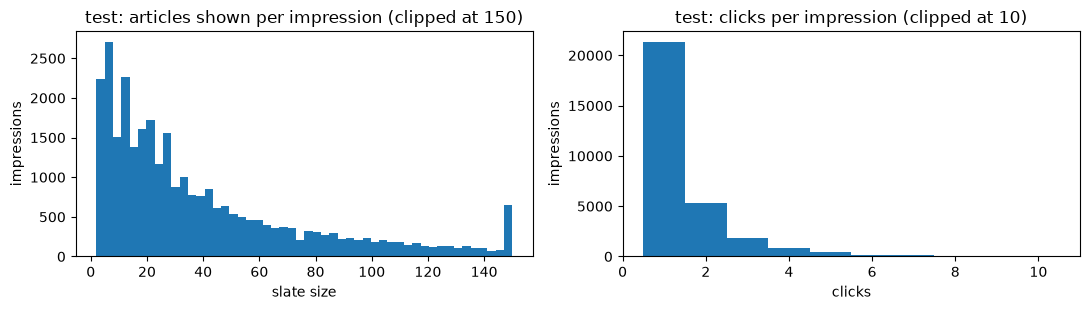

In [103]:
quantiles = [0.0, 0.25, 0.5, 0.75, 0.9, 0.99, 1.0]
target_slates = slate_sizes[TARGET_SPLIT]
display(
    target_slates.select(
        *[
            pl.col("slate_size").quantile(q).alias(f"size_q{int(q * 100)}")
            for q in quantiles
        ],
        pl.col("clicks").mean().alias("mean_clicks"),
        pl.col("clicks").max().alias("max_clicks"),
    )
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(target_slates["slate_size"].clip(upper_bound=150), bins=50)
axes[1].hist(target_slates["clicks"].clip(upper_bound=10), bins=np.arange(0.5, 11.5))
axes[0].set(
    title=f"{TARGET_SPLIT}: articles shown per impression (clipped at 150)",
    xlabel="slate size",
    ylabel="impressions",
)
axes[1].set(
    title=f"{TARGET_SPLIT}: clicks per impression (clipped at 10)",
    xlabel="clicks",
    ylabel="impressions",
)
plt.tight_layout()
plt.show()

## 2.2 Causal Click Histories

`request_profiles_<split>` stores, for every impression, the article rows the user clicked
**strictly before** that impression. RR4 reads the newest `HISTORY_CAP` of them. History length
also defines the cohorts used in section 5.3.

In [104]:
def load_profiles(split, impression_ids=None):
    """Map each impression to the article rows its user clicked strictly before the impression."""
    profiles = pl.scan_parquet(RUN / f"request_profiles_{split}" / "*.parquet").select(
        "impression_uid", "full_history_rows"
    )
    if impression_ids is not None:
        profiles = profiles.filter(pl.col("impression_uid").is_in(list(impression_ids)))
    profiles = profiles.collect()
    return dict(
        zip(
            profiles["impression_uid"].to_list(),
            profiles["full_history_rows"].to_list(),
        )
    )


def encode_histories(impression_ids, profiles):
    """Left-padded [impressions, HISTORY_CAP] article rows with the newest click last."""
    histories = np.zeros((len(impression_ids), HISTORY_CAP), dtype=np.int64)
    for index, uid in enumerate(impression_ids):
        history = profiles[uid][-HISTORY_CAP:]
        if len(history):
            histories[index, -len(history) :] = history
    return histories


HISTORY_BINS = [
    (0, 0, "0 clicks"),
    (1, 5, "1-5 clicks"),
    (6, 20, "6-20 clicks"),
    (21, None, "21+ clicks"),
]
COHORT_ORDER = [label for _, _, label in HISTORY_BINS]

target_profiles = load_profiles(TARGET_SPLIT)
history_length = pl.DataFrame(
    {
        "impression_uid": list(target_profiles),
        "history_length": [len(rows) for rows in target_profiles.values()],
    }
)
cohort = pl.lit(None, dtype=pl.Utf8)
for low, high, label in reversed(HISTORY_BINS):
    condition = (
        pl.col("history_length") >= low
        if high is None
        else pl.col("history_length").is_between(low, high)
    )
    cohort = pl.when(condition).then(pl.lit(label)).otherwise(cohort)
target_cohorts = history_length.with_columns(cohort.alias("cohort")).join(
    target_slates.select("impression_uid"), on="impression_uid", how="semi"
)
if target_cohorts.height != target_slates.height:
    raise ValueError(f"{TARGET_SPLIT}: some impressions have no request profile")

display(
    target_cohorts.group_by("cohort")
    .agg(
        pl.len().alias("impressions"),
        pl.col("history_length").median().alias("median_history"),
    )
    .with_columns((pl.col("impressions") / pl.col("impressions").sum()).alias("share"))
    .sort(pl.col("cohort").replace_strict({c: i for i, c in enumerate(COHORT_ORDER)}))
)

cohort,impressions,median_history,share
str,u32,f64,f64
"""0 clicks""",94,0.0,0.003105
"""1-5 clicks""",3128,4.0,0.103337
"""6-20 clicks""",10305,12.0,0.340436
"""21+ clicks""",16743,47.0,0.553122


## 2.3 Article Inputs

All article inputs are indexed by `article_row`; row 0 is padding. Every logged candidate must map
to an article row, otherwise RR4 cannot encode it.

In [105]:
article_index = pl.read_parquet(
    REPRESENTATIONS / "article_index.parquet",
    columns=["news_code", "article_row", "category_code", "subcategory_code"],
)
news_to_row = dict(
    zip(article_index["news_code"].to_list(), article_index["article_row"].to_list())
)

text_vectors = np.load(REPRESENTATIONS / "text64.npy", mmap_mode="r")
entity_vectors = np.load(REPRESENTATIONS / "article_entity100.npy", mmap_mode="r")
N_ARTICLES = text_vectors.shape[0]

# Category and subcategory codes per article row (0 = padding / unknown)
article_category = np.zeros(N_ARTICLES, dtype=np.int64)
article_subcategory = np.zeros(N_ARTICLES, dtype=np.int64)
article_category[article_index["article_row"].to_numpy()] = article_index[
    "category_code"
].to_numpy()
article_subcategory[article_index["article_row"].to_numpy()] = article_index[
    "subcategory_code"
].to_numpy()
print(
    f"{N_ARTICLES:,} article rows; {article_category.max()} categories; {article_subcategory.max()} subcategories"
)

for split in (TRAIN_SPLIT, TARGET_SPLIT):
    features, _ = scan_split(split)
    codes = features.select(pl.col("news_code").unique()).collect()["news_code"]
    unmapped = codes.filter(~codes.is_in(list(news_to_row)))
    if unmapped.len():
        raise ValueError(
            f"{split}: {unmapped.len()} logged articles have no article row"
        )
    print(f"{split}: all {codes.len():,} logged articles map to an article row")

51,283 article rows; 17 categories; 257 subcategories
train: all 13,536 logged articles map to an article row
test: all 6,144 logged articles map to an article row


# 3. Rule-Based Baselines

Both rules read causal features that feature engineering already computed, so they have no
trainable parameters. They are copied unchanged from `5_02_Reranking/1_Baseline`.

**Popularity** (`RR_popularity_baseline.ipynb`). For candidate $a$ at impression time $t$:

$$s(a,t) = \frac{c_{a,<t} + \alpha\, p_{<t}}{e_{a,<t} + \alpha}$$

where $c$ and $e$ are the article's earlier clicks and exposures and $p$ is the expanding global
CTR. Every user gets the same score.

**Content similarity** (`RR_content_similarity_baseline.ipynb`). The cosine between the candidate's
entity vector and the user's causal clicked-history entity profile (the rule selected on validation
there). A candidate with no valid vector scores $-2$, below every valid cosine in $[-1, 1]$; a user
with no profile falls back to the popularity score.

In [106]:
MISSING_SCORE = -2.0
POPULARITY_COLUMNS = ["smoothed_prior_article_ctr"]
CONTENT_COLUMNS = [
    "smoothed_prior_article_ctr",
    "entity_cosine",
    "entity_match_valid",
    "no_entity_profile",
]


def popularity_score(frame):
    """Score each candidate by its causal smoothed article CTR."""
    return frame["smoothed_prior_article_ctr"].to_numpy(dtype=float)


def content_score(frame):
    """Entity cosine to the causal profile; popularity when the user has no entity profile."""
    prior = frame["smoothed_prior_article_ctr"].to_numpy(dtype=float)
    entity = frame["entity_cosine"].to_numpy(dtype=float)
    entity_valid = frame["entity_match_valid"].to_numpy(dtype=bool)
    no_entity_profile = frame["no_entity_profile"].to_numpy(dtype=bool)
    return np.where(
        no_entity_profile, prior, np.where(entity_valid, entity, MISSING_SCORE)
    )


missing_columns = sorted(set(CONTENT_COLUMNS) - set(FEATURES))
if missing_columns:
    raise ValueError(
        f"Baseline columns missing from the feature schema: {missing_columns}"
    )

# 4. Train the RR4 Reranker

## 4.1 Sample Training Impressions

Copied from `RR_4_branch_interaction.ipynb`. Whole impressions are sampled because both listwise
losses compare candidates **within** an impression. Listwise losses need at least one click and
one non-click, so other impressions are dropped, and slates are capped at `MAX_CANDIDATES` (every
click kept, negatives sampled). 10% of impressions are held out to pick the best epoch, so
validation and test are never seen during training.

Two training frames are built, as in RR_4:

- the **`PREPROCESSOR_IMPRESSIONS` sample**: its fit part is what the tabular preprocessor is
  fitted on (RR_4 section 3.5);
- the **full training set**: what the final model is trained on (RR_4 stage 3).

In [107]:
def sample_train_impressions(max_impressions, columns):
    """Sample whole training impressions, then load every retained candidate in them."""
    feature_files = sorted((RUN / "ranking_features_train").glob("*.parquet"))
    label_files = sorted((RUN / "labels_train").glob("*.parquet"))
    impression_ids = (
        pl.scan_parquet(label_files)
        .select("impression_uid")
        .unique()
        .sort("impression_uid")
        .collect()["impression_uid"]
        .to_numpy()
    )
    rng = np.random.default_rng(SEED)
    chosen = rng.choice(
        impression_ids, size=min(max_impressions, len(impression_ids)), replace=False
    )

    keys = ["impression_uid", "news_code"]
    read_columns = list(dict.fromkeys([*keys, "prior_article_exposures", *columns]))
    features = (
        pl.scan_parquet(feature_files)
        .filter(pl.col("impression_uid").is_in(chosen))
        .select(read_columns)
        .collect()
        .to_pandas()
    )
    labels = (
        pl.scan_parquet(label_files)
        .filter(pl.col("impression_uid").is_in(chosen))
        .select(*keys, "clicked")
        .collect()
        .to_pandas()
    )
    train = features.merge(labels, on=keys, how="inner", validate="one_to_one")
    if not len(train) == len(features) == len(labels):
        raise ValueError("Training feature and label keys do not match")
    return train.sort_values(keys).reset_index(drop=True)


def cap_slates(frame, max_candidates):
    """Keep every click and at most `max_candidates` rows per impression (negatives sampled)."""
    rng = np.random.default_rng(SEED)
    keep = []
    for rows in frame.groupby("impression_uid", sort=False).indices.values():
        if len(rows) <= max_candidates:
            keep.append(rows)
            continue
        clicked = rows[frame["clicked"].to_numpy()[rows] == 1]
        unclicked = rows[frame["clicked"].to_numpy()[rows] == 0]
        n_negatives = max(max_candidates - len(clicked), 1)
        keep.append(
            np.concatenate(
                [
                    clicked,
                    rng.choice(
                        unclicked, size=min(n_negatives, len(unclicked)), replace=False
                    ),
                ]
            )
        )
    return frame.iloc[np.sort(np.concatenate(keep))].reset_index(drop=True)


def prepare_training_slates(max_impressions, holdout_fraction=HOLDOUT_FRACTION):
    """Sample, keep usable slates, cap them and split off `holdout_fraction` of the impressions."""
    train = sample_train_impressions(max_impressions, FEATURES)
    slate_stats = train.groupby("impression_uid")["clicked"].agg(["sum", "size"])
    usable = slate_stats.index[
        (slate_stats["sum"] > 0) & (slate_stats["sum"] < slate_stats["size"])
    ]
    train = cap_slates(
        train[train["impression_uid"].isin(usable)].reset_index(drop=True),
        MAX_CANDIDATES,
    )

    impression_ids = train["impression_uid"].drop_duplicates().to_numpy()
    holdout_ids = np.random.default_rng(SEED).choice(
        impression_ids, size=int(holdout_fraction * len(impression_ids)), replace=False
    )
    in_holdout = train["impression_uid"].isin(holdout_ids)
    return train[~in_holdout].reset_index(drop=True), train[in_holdout].reset_index(
        drop=True
    )


def load_full_slates(split):
    """Every logged pair of an evaluation split (no cap, no sampling), scored after every epoch."""
    keys = ["impression_uid", "news_code"]
    frame = (
        pl.scan_parquet(RUN / f"ranking_features_{split}" / "*.parquet")
        .select(*keys, *FEATURES)
        .join(pl.scan_parquet(RUN / f"labels_{split}" / "*.parquet").select(*keys, "clicked"), on=keys)
        .collect()
        .sort(keys)
        .to_pandas()
    )
    stats = frame.groupby("impression_uid")["clicked"].agg(["sum", "size"])
    usable = stats.index[(stats["sum"] > 0) & (stats["sum"] < stats["size"])]
    return frame[frame["impression_uid"].isin(usable)].reset_index(drop=True)


VALIDATION_SPLIT = "validation"
if not RR4_LOADED:
    validation_slates = load_full_slates(VALIDATION_SPLIT)
    print(
        f"Validation day for early stopping: {validation_slates['impression_uid'].nunique():,} "
        f"impressions, {len(validation_slates):,} candidates"
    )
    preprocessor_fit, _ = prepare_training_slates(PREPROCESSOR_IMPRESSIONS)
    fit, _ = prepare_training_slates(FULL_TRAIN_IMPRESSIONS or 10**9, holdout_fraction=0.0)
    print(
        f"Preprocessor sample: {preprocessor_fit['impression_uid'].nunique():,} fit impressions"
    )
    print(
        f"Full training set: {fit['impression_uid'].nunique():,} impressions, {len(fit):,} candidates "
        "(all used for training)"
    )
    print(f"Fit click rate: {fit['clicked'].mean():.4f}")

Validation day for early stopping: 31,624 impressions, 1,231,673 candidates
Preprocessor sample: 9,000 fit impressions
Full training set: 95,071 impressions, 3,150,275 candidates (all used for training)
Fit click rate: 0.0449


## 4.2 RR4 Model

Copied from `RR_4_branch_interaction.ipynb`. Only the `+metadata` branches are switched on.

```text
news vector = Linear+LayerNorm( text64 ; category emb ; subcategory emb ; Linear(entity100) )
user vector = self-attention over the newest 30 clicked news vectors -> additive attention pool
score       = MLP( [tabular features ; candidate news vector ; user vector] ) -> logit
```

**Additive attention** scores each element with a learned query vector and returns the weighted
sum. It pools the attended click history into one user vector.

In [108]:
class AdditiveAttention(nn.Module):
    """Pool a sequence of history states into one user vector with learned relevance weights."""

    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)
        self.query = nn.Parameter(torch.randn(dim) * 0.02)

    def forward(self, states, padding_mask):
        # states: [batch, history, dim]; padding_mask: [batch, history], True = padding
        all_padded = padding_mask.all(dim=1)
        safe_mask = padding_mask.clone()
        safe_mask[all_padded, 0] = False  # softmax needs one open slot

        scores = torch.tanh(self.proj(states)) @ self.query  # [batch, history]
        weights = torch.softmax(scores.masked_fill(safe_mask, -1e9), dim=1)
        weights = weights.masked_fill(padding_mask, 0.0)
        weights = weights / weights.sum(dim=1, keepdim=True).clamp(min=1e-8)
        return (weights.unsqueeze(-1) * states).sum(dim=1)  # [batch, dim]

**`NewsEncoder`** maps article rows to `MODEL_DIM` news vectors. The frozen text vector is
concatenated with learned category and subcategory embeddings and a projected entity vector.

In [109]:
class NewsEncoder(nn.Module):
    """Map article rows to MODEL_DIM news vectors from the enabled article inputs."""

    def __init__(self, config):
        super().__init__()
        if config["title_encoder"]:
            raise NotImplementedError(
                "This notebook's RR4 architecture does not use the title encoder"
            )
        self.config = config
        self.register_buffer(
            "text",
            torch.from_numpy(np.array(text_vectors, dtype=np.float32)),
            persistent=False,
        )
        width = self.text.shape[1]

        if config["metadata"]:
            self.register_buffer(
                "entity",
                torch.from_numpy(np.array(entity_vectors, dtype=np.float32)),
                persistent=False,
            )
            self.register_buffer(
                "category", torch.from_numpy(article_category), persistent=False
            )
            self.register_buffer(
                "subcategory", torch.from_numpy(article_subcategory), persistent=False
            )
            self.category_embedding = nn.Embedding(
                int(article_category.max()) + 1, 16, padding_idx=0
            )
            self.subcategory_embedding = nn.Embedding(
                int(article_subcategory.max()) + 1, 16, padding_idx=0
            )
            self.entity_projection = nn.Linear(self.entity.shape[1], 32)
            width += 16 + 16 + 32

        self.output = nn.Sequential(
            nn.Linear(width, MODEL_DIM), nn.LayerNorm(MODEL_DIM)
        )

    def forward(self, rows):
        # Encode each distinct article in the batch once, then scatter back to every position
        unique_rows, inverse = torch.unique(rows, return_inverse=True)
        parts = [self.text[unique_rows]]
        if self.config["metadata"]:
            parts += [
                self.category_embedding(self.category[unique_rows]),
                self.subcategory_embedding(self.subcategory[unique_rows]),
                self.entity_projection(self.entity[unique_rows]),
            ]
        return self.output(torch.cat(parts, dim=-1))[
            inverse
        ]  # rows.shape + [MODEL_DIM]

**`UserEncoder`** runs multi-head self-attention and a feed-forward block over the clicked news
vectors, then pools them with additive attention. Users with no history get a learned default
vector. The position, candidate-pooling and short-term branches are kept switchable as in RR_4 but
are off here.

In [110]:
class UserEncoder(nn.Module):
    """Encode the click history into per-candidate user vectors."""

    def __init__(self, config):
        super().__init__()
        self.config = config
        if config["position"]:
            self.position_embedding = nn.Embedding(HISTORY_CAP, MODEL_DIM)
        self.self_attention = nn.MultiheadAttention(
            MODEL_DIM, ATTENTION_HEADS, dropout=ATTENTION_DROPOUT, batch_first=True
        )
        self.norm1 = nn.LayerNorm(MODEL_DIM)
        self.feed_forward = nn.Sequential(
            nn.Linear(MODEL_DIM, 4 * MODEL_DIM),
            nn.ReLU(),
            nn.Dropout(ATTENTION_DROPOUT),
            nn.Linear(4 * MODEL_DIM, MODEL_DIM),
        )
        self.norm2 = nn.LayerNorm(MODEL_DIM)
        self.pool = AdditiveAttention(MODEL_DIM)
        self.default_user = nn.Parameter(torch.zeros(MODEL_DIM))
        if config["short_term"]:
            self.short_term = nn.GRU(MODEL_DIM, MODEL_DIM, batch_first=True)
            self.gate = nn.Linear(2 * MODEL_DIM, MODEL_DIM)

    @property
    def output_dim(self):
        return MODEL_DIM * (2 if self.config["candidate_pooling"] else 1)

    def forward(self, history, padding_mask, candidates):
        # history: [B, H, D]; padding_mask: [B, H] (True = padding); candidates: [B, W, D]
        empty = padding_mask.all(dim=1)
        safe_mask = padding_mask.clone()
        safe_mask[empty, -1] = False

        if self.config["position"]:
            ranks = torch.arange(HISTORY_CAP - 1, -1, -1, device=history.device)
            history = history + self.position_embedding(ranks)

        attended, _ = self.self_attention(
            history, history, history, key_padding_mask=safe_mask, need_weights=False
        )
        states = self.norm1(history + attended)
        states = self.norm2(states + self.feed_forward(states))
        states = states.masked_fill(padding_mask.unsqueeze(-1), 0.0)

        user = self.pool(states, padding_mask)
        if self.config["short_term"]:
            _, short = self.short_term(states[:, -SHORT_TERM_CAP:])
            short = short.squeeze(0)
            gate = torch.sigmoid(self.gate(torch.cat([user, short], dim=1)))
            user = gate * user + (1 - gate) * short
        user = torch.where(empty.unsqueeze(1), self.default_user.unsqueeze(0), user)
        user = user.unsqueeze(1).expand(-1, candidates.shape[1], -1)  # [B, W, D]

        if not self.config["candidate_pooling"]:
            return user
        scores = candidates @ states.transpose(1, 2) / np.sqrt(MODEL_DIM)  # [B, W, H]
        scores = scores.masked_fill(safe_mask.unsqueeze(1), -1e9)
        weights = torch.softmax(scores, dim=-1).masked_fill(
            padding_mask.unsqueeze(1), 0.0
        )
        return torch.cat([user, weights @ states], dim=-1)

**`BranchReranker`** concatenates the enabled branches and scores them with a two-layer MLP:
`[tabular ; candidate news vector ; user vector] -> Dense 256 -> ReLU -> Dropout -> Dense 64 -> ReLU -> Dropout -> logit`.

In [111]:
class BranchReranker(nn.Module):
    """Score candidates from the enabled tabular, news and user branches."""

    def __init__(self, config, tabular_width):
        super().__init__()
        if config["user_encoder"] and not config["text"]:
            raise ValueError("The user encoder needs the news encoder (text=True)")
        if not (config["tabular"] or config["text"]):
            raise ValueError("At least one of the tabular or text branches must be on")
        self.config = config
        width = tabular_width if config["tabular"] else 0
        if config["text"]:
            self.news_encoder = NewsEncoder(config)
            width += MODEL_DIM
        if config["user_encoder"]:
            self.user_encoder = UserEncoder(config)
            width += self.user_encoder.output_dim

        layers = []
        for hidden in HIDDEN_DIMS:
            layers.extend([nn.Linear(width, hidden), nn.ReLU(), nn.Dropout(DROPOUT)])
            width = hidden
        layers.append(nn.Linear(width, 1))
        self.scorer = nn.Sequential(*layers)

    def forward(self, tabular, candidate_rows, history_rows):
        # tabular: [B, W, T]; candidate_rows: [B, W]; history_rows: [B, H] -> logits [B, W]
        parts = [tabular] if self.config["tabular"] else []
        if self.config["text"]:
            candidates = self.news_encoder(candidate_rows)
            parts.append(candidates)
            if self.config["user_encoder"]:
                history = self.news_encoder(history_rows)
                parts.append(self.user_encoder(history, history_rows.eq(0), candidates))
        return self.scorer(torch.cat(parts, dim=-1)).squeeze(-1)

## 4.3 Preprocessor and Impression Batches

The preprocessor median-imputes and standardises numeric features and one-hot encodes the
categoricals. It is fitted on the preprocessor sample's fit impressions only, as in RR_4.

Training and the per-epoch validation check work on padded impression batches: `rows` and `mask` are
`[impressions, candidates]`, and each impression's history is encoded once and shared by all of its
candidates. Tabular features are preprocessed one batch at a time, which keeps memory flat on the
full training set.

In [112]:
def build_preprocessor():
    """Median-impute and standardise numeric inputs; mode-impute and one-hot encode categoricals."""
    numeric = Pipeline(
        [
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]
    )
    categorical = Pipeline(
        [
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    return ColumnTransformer(
        [
            ("numeric", numeric, NUMERIC),
            ("categorical", categorical, CATEGORICAL),
        ]
    )


if RR4_LOADED:
    preprocessor = joblib.load(PREPROCESSOR_PATH)
    TABULAR_WIDTH = RR4_CHECKPOINT_META["tabular_width"]
    print("Loaded preprocessor:", PREPROCESSOR_PATH)
else:
    preprocessor = build_preprocessor().fit(preprocessor_fit[FEATURES])
    joblib.dump(preprocessor, PREPROCESSOR_PATH)
    TABULAR_WIDTH = preprocessor.transform(preprocessor_fit[FEATURES].head(1)).shape[1]
    print("Saved preprocessor:", PREPROCESSOR_PATH)
print(f"Tabular width: {TABULAR_WIDTH}")


def build_impression_data(frame, precompute_tabular=True, split=TRAIN_SPLIT):
    """Arrays for padded impression batches over a training frame."""
    uids = frame["impression_uid"].drop_duplicates().tolist()
    candidate_rows = frame["news_code"].map(news_to_row)
    if candidate_rows.isna().any():
        raise ValueError("A candidate is missing its article row")
    return {
        "groups": [
            rows.astype(np.int64)
            for rows in frame.groupby("impression_uid", sort=False).indices.values()
        ],
        "histories": torch.from_numpy(
            encode_histories(uids, load_profiles(split, uids))
        ),
        "tabular": (
            torch.from_numpy(
                preprocessor.transform(frame[FEATURES]).astype(np.float32, copy=False)
            )
            if precompute_tabular
            else None
        ),
        "features": None
        if precompute_tabular
        else frame[FEATURES].reset_index(drop=True),
        "candidates": torch.from_numpy(candidate_rows.to_numpy(np.int64)),
        "labels": torch.from_numpy(frame["clicked"].to_numpy(np.float32)),
    }


def impression_batches(data, order):
    """Yield (tabular, candidates, histories, labels, mask) for batches of impressions."""
    for start in range(0, len(order), BATCH_IMPRESSIONS):
        batch = order[start : start + BATCH_IMPRESSIONS]
        groups = [data["groups"][index] for index in batch]
        width = max(len(group) for group in groups)
        rows = torch.zeros((len(batch), width), dtype=torch.long)
        mask = torch.zeros((len(batch), width), dtype=torch.bool)
        for position, group in enumerate(groups):
            rows[position, : len(group)] = torch.from_numpy(group)
            mask[position, : len(group)] = True
        if data["tabular"] is not None:
            tabular = data["tabular"][rows]
        else:
            raw = data["features"].iloc[rows.reshape(-1).numpy()]
            tabular = torch.from_numpy(
                preprocessor.transform(raw).astype(np.float32, copy=False)
            ).reshape(*rows.shape, -1)
        yield (
            tabular.to(DEVICE),
            data["candidates"][rows].to(DEVICE),
            data["histories"][torch.as_tensor(batch)].to(DEVICE),
            (data["labels"][rows] * mask).to(DEVICE),  # padding never counts as a click
            mask.to(DEVICE),
        )


if not RR4_LOADED:
    fit_data = build_impression_data(fit, precompute_tabular=False)
    validation_data = build_impression_data(
        validation_slates, precompute_tabular=False, split=VALIDATION_SPLIT
    )

Saved preprocessor: /Users/numkoos/Downloads/v3-mindsmall/5_Models/5_03_Pipeline_Evaluation/artifacts/reranker_logged_slates/reranker/preprocessor.joblib
Tabular width: 246


## 4.4 Losses and Training Loop

The selected loss is `softmax+lambda_ndcg` = `0.5 * softmax + 0.5 * lambda_ndcg`:

- **Listwise softmax**: for each click, cross-entropy of that click against every unclicked
  candidate in its impression: $-\log \frac{e^{s^+}}{e^{s^+} + \sum_{j \in neg} e^{s_j}}$.
  It favours MRR-style "click on top" behaviour.
- **LambdaNDCG@K**: a RankNet loss on (click, non-click) pairs weighted by how much swapping them
  would change nDCG@K, so it concentrates on the top-K order the metric reads.

Each epoch shuffles the training impressions. After every epoch the model scores every validation-day
(13 Nov) slate in evaluation mode, recording the validation loss and validation nDCG@10. The epoch
with the best validation nDCG@10 is kept, and training stops once it has not improved for
`PATIENCE` epochs. This is the MIND protocol (the last day before test is the validation set, and
model choices are made on it); the test day stays untouched until section 5.


In [113]:
def listwise_softmax_loss(logits, labels, mask):
    """Mean over clicks of -log softmax(click vs. all unclicked candidates in its impression)."""
    positive = (labels > 0) & mask
    negative = (labels == 0) & mask
    negative_lse = torch.logsumexp(
        logits.masked_fill(~negative, float("-inf")), dim=1, keepdim=True
    )
    log_probability = logits - torch.logaddexp(logits, negative_lse)
    return -(log_probability * positive).sum() / positive.sum().clamp_min(1)


def lambda_ndcg_loss(logits, labels, mask, k=NDCG_K):
    """RankNet loss weighted by detached |Delta nDCG@k| for every (click, non-click) pair."""
    masked_logits = logits.masked_fill(~mask, float("-inf"))
    ranks = masked_logits.argsort(dim=1, descending=True).argsort(dim=1).add(1).detach()
    gains = (torch.pow(2.0, labels) - 1.0) * mask
    discounts = (1.0 / torch.log2(ranks.float() + 1.0)) * (ranks <= k) * mask

    ideal_labels = (
        labels.masked_fill(~mask, float("-inf")).sort(dim=1, descending=True).values
    )
    ideal_mask = torch.isfinite(ideal_labels)
    ideal_labels = ideal_labels.clamp_min(0)
    positions = torch.arange(1, logits.shape[1] + 1, device=logits.device)
    ideal_discounts = (1.0 / torch.log2(positions.float() + 1.0)) * (positions <= k)
    idcg = (
        ((torch.pow(2.0, ideal_labels) - 1.0) * ideal_discounts * ideal_mask)
        .sum(dim=1)
        .clamp_min(1e-12)
    )

    score_diff = logits.unsqueeze(2) - logits.unsqueeze(1)
    delta_ndcg = (
        (gains.unsqueeze(2) - gains.unsqueeze(1))
        * (discounts.unsqueeze(2) - discounts.unsqueeze(1))
    ).abs()
    weights = delta_ndcg / idcg[:, None, None]
    valid_pairs = (
        (labels.unsqueeze(2) > labels.unsqueeze(1))
        & mask.unsqueeze(2)
        & mask.unsqueeze(1)
    )
    weights = weights * valid_pairs
    return (F.softplus(-score_diff) * weights).sum() / weights.sum().clamp_min(1e-12)


def combined_loss(**weights):
    """Weighted sum of base losses, e.g. combined_loss(softmax=0.5, lambda_ndcg=0.5)."""
    base = {"softmax": listwise_softmax_loss, "lambda_ndcg": lambda_ndcg_loss}

    def loss(logits, labels, mask):
        return sum(
            weight * base[name](logits, labels, mask)
            for name, weight in weights.items()
        )

    return loss


LOSSES = {"softmax+lambda_ndcg": combined_loss(softmax=0.5, lambda_ndcg=0.5)}


def batch_ndcg(logits, labels, mask, k=10):
    """Mean nDCG@k over a batch of impressions (retained candidates only)."""
    order = logits.masked_fill(~mask, float("-inf")).argsort(dim=1, descending=True)[
        :, :k
    ]
    discounts = 1.0 / torch.log2(
        torch.arange(2, order.shape[1] + 2, device=logits.device).float()
    )
    dcg = (labels.gather(1, order) * discounts).sum(dim=1)
    ideal = (
        labels.masked_fill(~mask, 0)
        .sort(dim=1, descending=True)
        .values[:, : order.shape[1]]
        * discounts
    ).sum(dim=1)
    return (dcg / ideal.clamp_min(1e-12)).mean().item()


def evaluate_batches(model, data, loss_fn):
    """Mean loss and mean nDCG@10 over every impression in `data` (evaluation mode, no gradients)."""
    losses, ndcgs = [], []
    with torch.no_grad():
        for tabular, candidates, histories, labels, mask in impression_batches(
            data, np.arange(len(data["groups"]))
        ):
            logits = model(tabular, candidates, histories)
            losses.append(loss_fn(logits, labels, mask).item())
            ndcgs.append(batch_ndcg(logits, labels, mask) * len(labels))
    return float(np.mean(losses)), float(np.sum(ndcgs) / len(data["groups"]))


def train_model(config, loss_name, fit_data, validation_data, epochs=EPOCHS, patience=None):
    """Train one architecture with one loss; return the model from the best validation-nDCG@10 epoch."""
    torch.manual_seed(SEED)
    model = BranchReranker(config, TABULAR_WIDTH).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    loss_fn = LOSSES[loss_name]
    rng = np.random.default_rng(SEED)
    best = {"ndcg": -1.0, "epoch": 0, "state": None}
    history = []

    for epoch in range(1, epochs + 1):
        started = time.monotonic()
        model.train()
        losses = []
        for tabular, candidates, histories, labels, mask in impression_batches(
            fit_data, rng.permutation(len(fit_data["groups"]))
        ):
            optimizer.zero_grad()
            loss = loss_fn(model(tabular, candidates, histories), labels, mask)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())

        model.eval()
        validation_loss, validation_ndcg = evaluate_batches(model, validation_data, loss_fn)
        history.append(
            {
                "epoch": epoch,
                "loss": float(np.mean(losses)),
                "validation_loss": validation_loss,
                "validation_ndcg_at_10": validation_ndcg,
                "minutes": (time.monotonic() - started) / 60,
            }
        )
        print(
            f"  epoch {epoch}/{epochs}: {loss_name} loss {np.mean(losses):.4f}, "
            f"validation loss {validation_loss:.4f}, validation nDCG@10 {validation_ndcg:.4f}"
        )
        if validation_ndcg > best["ndcg"]:
            best = {
                "ndcg": validation_ndcg,
                "epoch": epoch,
                "state": {
                    key: value.detach().cpu().clone()
                    for key, value in model.state_dict().items()
                },
            }
        elif patience is not None and epoch - best["epoch"] >= patience:
            print(
                f"  early stopping: no validation improvement for {patience} epochs; keeping epoch {best['epoch']}"
            )
            break

    model.load_state_dict(best["state"])
    model.best_epoch, model.best_validation_ndcg = best["epoch"], best["ndcg"]
    model.history = history
    return model

## 4.5 Train or Load RR4

In [114]:
if RR4_LOADED:
    model = BranchReranker(CONFIG, RR4_CHECKPOINT_META["tabular_width"]).to(DEVICE)
    model.load_state_dict(RR4_CHECKPOINT_META["state_dict"], strict=True)
    model.best_epoch = RR4_CHECKPOINT_META["best_epoch"]
    # Older checkpoints stopped on a 10% training holdout and stored "holdout_ndcg" instead
    model.best_validation_ndcg = RR4_CHECKPOINT_META.get(
        "validation_ndcg", RR4_CHECKPOINT_META.get("holdout_ndcg")
    )
    model.stopping_metric = "validation" if "validation_ndcg" in RR4_CHECKPOINT_META else "holdout"
    model.history = RR4_CHECKPOINT_META.get("history", [])
    print("Loaded RR4:", RR4_CHECKPOINT_PATH)
else:
    started = time.monotonic()
    model = train_model(
        CONFIG,
        LOSS_NAME,
        fit_data,
        validation_data,
        epochs=EPOCHS,
        patience=PATIENCE,
    )
    model.stopping_metric = "validation"
    torch.save(
        {
            "state_dict": {
                key: value.detach().cpu() for key, value in model.state_dict().items()
            },
            "config": CONFIG,
            "loss": LOSS_NAME,
            "tabular_width": TABULAR_WIDTH,
            "features": FEATURES,
            "training": TRAINING_SETTINGS,
            "best_epoch": int(model.best_epoch),
            "validation_ndcg": float(model.best_validation_ndcg),
            "history": model.history,
            "seed": SEED,
        },
        RR4_CHECKPOINT_PATH,
    )
    print(
        f"Saved RR4: {RR4_CHECKPOINT_PATH} ({(time.monotonic() - started) / 60:.1f} min)"
    )
    del fit_data, validation_data, validation_slates

model.eval()
print(f"Best epoch: {model.best_epoch} ({model.stopping_metric} nDCG@10 {model.best_validation_ndcg:.4f})")
print(
    f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)
if model.history:
    display(pd.DataFrame(model.history).round(4))

  epoch 1/20: softmax+lambda_ndcg loss 1.6560, validation loss 1.7444, validation nDCG@10 0.4633
  epoch 2/20: softmax+lambda_ndcg loss 1.6226, validation loss 1.7393, validation nDCG@10 0.4645
  epoch 3/20: softmax+lambda_ndcg loss 1.6085, validation loss 1.7297, validation nDCG@10 0.4664
  epoch 4/20: softmax+lambda_ndcg loss 1.5970, validation loss 1.7309, validation nDCG@10 0.4663
  epoch 5/20: softmax+lambda_ndcg loss 1.5892, validation loss 1.7276, validation nDCG@10 0.4674
  epoch 6/20: softmax+lambda_ndcg loss 1.5804, validation loss 1.7338, validation nDCG@10 0.4670
  epoch 7/20: softmax+lambda_ndcg loss 1.5729, validation loss 1.7239, validation nDCG@10 0.4667


2026-11-09 20:01:14.381 python[76708:12755466] Error creating directory 
 The volume ‚ÄúMacintosh HD‚Äù is out of space. You can‚Äôt save the file ‚Äúmpsgraph-76708-2026-11-09_20_01_14-526136372‚Äù because the volume ‚ÄúMacintosh HD‚Äù is out of space.
2026-11-09 20:01:14.407 python[76708:12755466] Error creating directory 
 The volume ‚ÄúMacintosh HD‚Äù is out of space. You can‚Äôt save the file ‚Äúmpsgraph-76708-2026-11-09_20_01_14-1601193962‚Äù because the volume ‚ÄúMacintosh HD‚Äù is out of space.
2026-11-09 20:01:14.429 python[76708:12755466] Error creating directory 
 The volume ‚ÄúMacintosh HD‚Äù is out of space. You can‚Äôt save the file ‚Äúmpsgraph-76708-2026-11-09_20_01_14-788506699‚Äù because the volume ‚ÄúMacintosh HD‚Äù is out of space.
2026-11-09 20:01:14.449 python[76708:12755466] Error creating directory 
 The volume ‚ÄúMacintosh HD‚Äù is out of space. You can‚Äôt save the file ‚Äúmpsgraph-76708-2026-11-09_20_01_14-3237465817‚Äù because the volume ‚ÄúMacintosh HD‚Äù is 

  epoch 8/20: softmax+lambda_ndcg loss 1.5653, validation loss 1.7311, validation nDCG@10 0.4642
  early stopping: no validation improvement for 3 epochs; keeping epoch 5
Saved RR4: /Users/numkoos/Downloads/v3-mindsmall/5_Models/5_03_Pipeline_Evaluation/artifacts/reranker_logged_slates/reranker/model.pt (13.7 min)
Best epoch: 5 (validation nDCG@10 0.4674)
Trainable parameters: 182,817


,epoch,loss,validation_loss,validation_ndcg_at_10,minutes
0,1,1.6560,1.7444,0.4633,1.1725
1,2,1.6226,1.7393,0.4645,1.4069
2,3,1.6085,1.7297,0.4664,1.7990
3,4,1.5970,1.7309,0.4663,1.8467
4,5,1.5892,1.7276,0.4674,1.7421
5,6,1.5804,1.7338,0.4670,1.8231
6,7,1.5729,1.7239,0.4667,1.7967
7,8,1.5653,1.7311,0.4642,2.0716


# 5. Score and Evaluate the Logged Slates

Each model writes one score per logged (impression, article) pair of the target split to
`<data path>/5_Models/5_03_Pipeline_Evaluation/artifacts/reranker_logged_slates/scores/<model>_<split>_scores.parquet`. RR4 scores pointwise: each candidate is scored
as a one-article slate with its own history, so candidates never influence each other.

`rr_evaluation.py` rejects incomplete or duplicate score files and breaks ties by ascending
`news_code`. Reported metrics (over complete logged slates, at each cutoff in `K_VALUES`):

| Metric | Meaning |
|---|---|
| `mrr` | Reciprocal rank of the first click |
| `ndcg_at_k` | Binary-click nDCG over the top `k` |
| `recall_at_k` | Share of an impression's clicks in the top `k`, averaged over impressions |
| `click_retention_at_k` | Pooled share of all clicks in the top `k` |
| `engaged_impression_rate_at_k` | Share of impressions with at least one click in the top `k` |
| `observed_ctr_at_k` | Clicks per article in the top `k` (lift is relative to popularity) |

## 5.1 Overall Results

In [115]:
def rr4_predictor(model, profiles):
    """Wrap the trained model and a split's histories as a predict(frame) function."""

    def predict(frame):
        uids = frame["impression_uid"].drop_duplicates().tolist()
        histories = encode_histories(uids, profiles)
        history_index = (
            frame["impression_uid"]
            .map(pd.Series(np.arange(len(uids)), index=uids))
            .to_numpy()
        )
        tabular = preprocessor.transform(frame[FEATURES]).astype(np.float32, copy=False)
        candidates = np.array(frame["news_code"].map(news_to_row), dtype=np.int64)

        scores = []
        with torch.no_grad():
            for start in range(0, len(frame), SCORING_BATCH_ROWS):
                stop = start + SCORING_BATCH_ROWS
                logits = model(
                    torch.from_numpy(tabular[start:stop]).unsqueeze(1).to(DEVICE),
                    torch.from_numpy(candidates[start:stop]).unsqueeze(1).to(DEVICE),
                    torch.from_numpy(histories[history_index[start:stop]]).to(DEVICE),
                )
                scores.append(torch.sigmoid(logits.squeeze(1)).cpu().numpy())
        return np.concatenate(scores)

    return predict


SCORERS = {
    POPULARITY_MODEL: (popularity_score, POPULARITY_COLUMNS),
    CONTENT_MODEL: (content_score, CONTENT_COLUMNS),
    RR4_MODEL: (rr4_predictor(model, target_profiles), FEATURES),
}
evaluator = RerankingEvaluator(split=TARGET_SPLIT, feature_run=RUN)


def score_path(model_name):
    return SCORE_DIR / f"{model_name}_{TARGET_SPLIT}_scores.parquet"


overall_rows, timings = [], []
for model_name in MODEL_NAMES:
    started = time.monotonic()
    predict, columns = SCORERS[model_name]
    write_scores(
        predict,
        split=TARGET_SPLIT,
        feature_run=RUN,
        output_path=score_path(model_name),
        columns=columns,
    )
    result = evaluator.evaluate(
        score_path(model_name), model_name=model_name, k_values=K_VALUES
    )
    overall_rows.append(result)
    timings.append(
        {"model": model_name, "seconds": round(time.monotonic() - started, 1)}
    )
    print(f"Evaluated {model_name}: nDCG@10 {result['ndcg_at_10'][0]:.4f}")

overall = compare_results(overall_rows, baseline_model=POPULARITY_MODEL)
display(pl.DataFrame(timings))

Evaluated popularity_smoothed_prior_article_ctr: nDCG@10 0.3557
Evaluated content_entity_cosine: nDCG@10 0.3056
Evaluated attention_reranker: nDCG@10 0.4439


model,seconds
str,f64
"""popularity_smoothed_prior_arti…",5.0
"""content_entity_cosine""",3.0
"""attention_reranker""",36.1


In [116]:
def metric_table(results, metrics):
    """Models as rows, one column per metric@k, best model first."""
    return (
        results.sort(f"ndcg_at_{K_VALUES[1]}", descending=True)
        .with_columns(pl.col("model").replace_strict(MODEL_LABELS))
        .select(
            "model", "impressions", *[f"{m}_at_{k}" for m in metrics for k in K_VALUES]
        )
    )


print(f"{TARGET_SPLIT.upper()}: ranking accuracy")
display(
    overall.with_columns(pl.col("model").replace_strict(MODEL_LABELS))
    .select("model", "impressions", "mrr")
    .sort("mrr", descending=True)
)
display(metric_table(overall, ["ndcg", "recall"]))
print(f"{TARGET_SPLIT.upper()}: clicks reached")
display(metric_table(overall, ["engaged_impression_rate", "observed_ctr"]))
display(
    overall.with_columns(pl.col("model").replace_strict(MODEL_LABELS)).select(
        "model", *[f"observed_ctr_at_{k}_lift_pct_vs_baseline" for k in K_VALUES]
    )
)

TEST: ranking accuracy


model,impressions,mrr
str,i64,f64
"""RR4 attention reranker""",30270,0.410422
"""Popularity (rule)""",30270,0.323149
"""Content similarity (rule)""",30270,0.268094


model,impressions,ndcg_at_5,ndcg_at_10,ndcg_at_30,recall_at_5,recall_at_10,recall_at_30
str,i64,f64,f64,f64,f64,f64,f64
"""RR4 attention reranker""",30270,0.384257,0.44394,0.505096,0.510907,0.680146,0.901246
"""Popularity (rule)""",30270,0.292374,0.355655,0.431714,0.408817,0.590234,0.870441
"""Content similarity (rule)""",30270,0.245041,0.305575,0.381081,0.361378,0.535904,0.816453


TEST: clicks reached


model,impressions,engaged_impression_rate_at_5,engaged_impression_rate_at_10,engaged_impression_rate_at_30,observed_ctr_at_5,observed_ctr_at_10,observed_ctr_at_30
str,i64,f64,f64,f64,f64,f64,f64
"""RR4 attention reranker""",30270,0.597985,0.763066,0.943343,0.139061,0.102609,0.062308
"""Popularity (rule)""",30270,0.484539,0.675884,0.920515,0.109348,0.087402,0.059303
"""Content similarity (rule)""",30270,0.416188,0.606046,0.876016,0.09162,0.075681,0.054109


model,observed_ctr_at_5_lift_pct_vs_baseline,observed_ctr_at_10_lift_pct_vs_baseline,observed_ctr_at_30_lift_pct_vs_baseline
str,f64,f64,f64
"""RR4 attention reranker""",27.173028,17.399634,5.067842
"""Popularity (rule)""",0.0,0.0,0.0
"""Content similarity (rule)""",-16.212321,-13.409962,-8.757841


## 5.2 Comparison with the RR_4 Run

The same architecture and loss trained in `RR_4_branch_interaction.ipynb` (stage 3) recorded these
metrics. RR_4 early-stopped on a random 10% holdout of training impressions, while this notebook
trains on every training impression and early-stops on the validation day, so the numbers should be
close but not identical. GPU kernels are also not bit-for-bit deterministic. A large gap means the
data or settings differ.

In [117]:
RR4_REFERENCE = {  # RR_4_branch_interaction.ipynb, branch_plus_metadata__softmax_plus_lambda_ndcg__full_data
    "validation": {
        "best_epoch": 7,
        "mrr": 0.429742,
        "ndcg_at_5": 0.407457,
        "ndcg_at_10": 0.462785,
        "recall_at_10": 0.692432,
    },
    "test": {
        "best_epoch": 7,
        "mrr": 0.411545,
        "ndcg_at_5": 0.385302,
        "ndcg_at_10": 0.444391,
        "recall_at_10": 0.678671,
    },
}
row = overall.filter(pl.col("model") == RR4_MODEL).row(0, named=True)
row = {**row, "best_epoch": model.best_epoch}
comparison = pl.DataFrame(
    [
        {
            "metric": metric,
            "rr4_notebook": float(reference),
            "this_notebook": float(row[metric]),
            "difference": float(row[metric] - reference),
        }
        for metric, reference in RR4_REFERENCE[TARGET_SPLIT].items()
    ]
)
display(comparison)

metric,rr4_notebook,this_notebook,difference
str,f64,f64,f64
"""best_epoch""",7.0,5.0,-2.0
"""mrr""",0.411545,0.410422,-0.001123
"""ndcg_at_5""",0.385302,0.384257,-0.001045
"""ndcg_at_10""",0.444391,0.44394,-0.000451
"""recall_at_10""",0.678671,0.680146,0.001475


## 5.3 Results by User History

Impressions are grouped by how many clicks the user had **before** the impression. Popularity ignores
the user, so this shows where personalisation helps, and where there is nothing to personalise from
(`0 clicks`, where the content rule falls back to popularity).

TEST: nDCG@10 by user history


cohort,impressions,Popularity (rule),Content similarity (rule),RR4 attention reranker
str,i64,f64,f64,f64
"""0 clicks""",94,0.321006,0.321006,0.353989
"""1-5 clicks""",3128,0.379691,0.344859,0.427517
"""6-20 clicks""",10305,0.37278,0.321296,0.449188
"""21+ clicks""",16743,0.340819,0.288474,0.444283


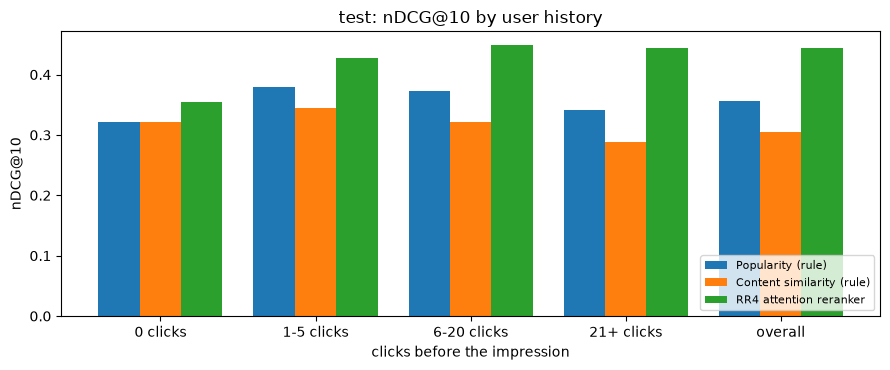

In [118]:
cohort_rows = [
    evaluator.evaluate(
        score_path(model_name),
        model_name=model_name,
        impression_cohorts=target_cohorts,
        k_values=K_VALUES,
    )
    for model_name in MODEL_NAMES
]
by_history = compare_results(cohort_rows, baseline_model=POPULARITY_MODEL)

print(f"{TARGET_SPLIT.upper()}: nDCG@10 by user history")
display(
    by_history.with_columns(pl.col("model").replace_strict(MODEL_LABELS))
    .pivot(on="model", index=["cohort", "impressions"], values="ndcg_at_10")
    .select("cohort", "impressions", *[MODEL_LABELS[name] for name in MODEL_NAMES])
    .sort(pl.col("cohort").replace_strict({c: i for i, c in enumerate(COHORT_ORDER)}))
)

groups = COHORT_ORDER + ["overall"]
width = 0.8 / len(MODEL_NAMES)
fig, ax = plt.subplots(figsize=(9, 3.8))
for index, model_name in enumerate(MODEL_NAMES):
    values = [
        by_history.filter((pl.col("model") == model_name) & (pl.col("cohort") == c))[
            "ndcg_at_10"
        ][0]
        for c in COHORT_ORDER
    ] + [overall.filter(pl.col("model") == model_name)["ndcg_at_10"][0]]
    ax.bar(
        np.arange(len(groups)) + (index - (len(MODEL_NAMES) - 1) / 2) * width,
        values,
        width,
        label=MODEL_LABELS[model_name],
    )
ax.set_xticks(np.arange(len(groups)), groups)
ax.set(
    title=f"{TARGET_SPLIT}: nDCG@10 by user history",
    xlabel="clicks before the impression",
    ylabel="nDCG@10",
)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

# 6. Example Slate

One target-split impression, ranked by each model side by side. The click label is shown only to
read the example; no model sees it.

In [119]:
EXAMPLE_TOP_N = 10
example_uid = (
    target_slates.filter(
        pl.col("slate_size").is_between(15, 40) & (pl.col("clicks") == 1)
    )
    .join(target_cohorts.filter(pl.col("history_length") >= 6), on="impression_uid")
    .sort("impression_uid")["impression_uid"][0]
)
slate = (
    target_labels.filter(pl.col("impression_uid") == example_uid)
    .select("news_code", "clicked")
    .collect()
)
for model_name in MODEL_NAMES:
    ranks = (
        pl.scan_parquet(score_path(model_name))
        .filter(pl.col("impression_uid") == example_uid)
        .collect()
        .sort(["score", "news_code"], descending=[True, False])
        .with_row_index("rank", offset=1)
        .select("news_code", pl.col("rank").alias(MODEL_LABELS[model_name]))
    )
    slate = slate.join(ranks, on="news_code")

example_history = target_cohorts.filter(pl.col("impression_uid") == example_uid)[
    "history_length"
][0]
print(
    f"Impression {example_uid}: {slate.height} shown articles, user history {example_history} clicks"
)
display(slate.sort(MODEL_LABELS[RR4_MODEL]).head(EXAMPLE_TOP_N))
print("Rank of the clicked article under each model:")
display(slate.filter(pl.col("clicked") == 1))

Impression 20000003: 36 shown articles, user history 18 clicks


news_code,clicked,Popularity (rule),Content similarity (rule),RR4 attention reranker
i64,i8,u32,u32,u32
59685,0,3,6,1
40109,0,10,31,2
35389,0,4,12,3
16844,0,14,22,4
23814,1,7,14,5
36226,0,20,29,6
49712,0,5,2,7
23446,0,1,25,8
48722,0,18,9,9


Rank of the clicked article under each model:


news_code,clicked,Popularity (rule),Content similarity (rule),RR4 attention reranker
i64,i8,u32,u32,u32
23814,1,7,14,5


# 7. Save Outputs

- `RESULTS/rr_only_logged_slates_<split>.csv`: one row per model
- `RESULTS/rr_only_logged_slates_<split>_by_history.csv`: one row per model and history cohort
- `RESULTS/rr_only_logged_slates_<split>.json`: inputs, RR4 checkpoint and training settings, headline metrics

The files use an `rr_only_` prefix so `results.ipynb`, which collects the end-to-end `pipeline_*.csv`
files, does not mix logged-slate results into the pipeline comparison.

In [120]:
results_path = RESULTS / f"rr_only_logged_slates_{TARGET_SPLIT}.csv"
by_history_path = RESULTS / f"rr_only_logged_slates_{TARGET_SPLIT}_by_history.csv"
metadata_path = RESULTS / f"rr_only_logged_slates_{TARGET_SPLIT}.json"

overall.write_csv(results_path)
by_history.write_csv(by_history_path)
metadata_path.write_text(
    json.dumps(
        {
            "pipeline": "logged MIND slates + rule baselines and RR4 attention reranker",
            "split": TARGET_SPLIT,
            "k": list(K_VALUES),
            "impressions": int(target_slates.height),
            "seed": SEED,
            "models": MODEL_LABELS,
            "rr4_checkpoint": str(RR4_CHECKPOINT_PATH),
            "rr4_preprocessor": str(PREPROCESSOR_PATH),
            "rr4_reused": bool(RR4_LOADED),
            "rr4_best_epoch": int(model.best_epoch),
            "rr4_early_stopping": f"{model.stopping_metric} nDCG@10",
            "rr4_early_stopping_ndcg": float(model.best_validation_ndcg),
            "architecture": CONFIG,
            "training": TRAINING_SETTINGS,
            "history_cohorts": COHORT_ORDER,
            "metrics": {
                row["model"]: {
                    name: row[name]
                    for name in ("mrr", *[f"ndcg_at_{k}" for k in K_VALUES])
                }
                for row in overall.iter_rows(named=True)
            },
        },
        indent=2,
    )
)
for path in (results_path, by_history_path, metadata_path):
    print("Saved:", path)

Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_logged_slates_test.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_logged_slates_test_by_history.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_logged_slates_test.json


# 8. Tabular Feature Importance

RR4 scores each candidate from three inputs: the **tabular features** from feature engineering, the
candidate's news vector and the user vector. This section asks how much the final ranking depends
on each tabular feature group, using two complementary methods on the target split.

**Feature groups** come from `feature_schema.json`:

| Group | What it describes |
|---|---|
| `content` | the article itself: category, word counts, entity coverage |
| `history` | how much click history the user has |
| `match` | similarity between the candidate and the user's history (text, entity, category) |
| `repeat` | the user's earlier exposures to and clicks on this exact article |
| `popularity` | the article's causal exposures, clicks and smoothed CTR |
| `freshness` | article age |
| `multi_interest` | match against the user's separate interest clusters |
| `half_life` | the article's estimated attention half-life and staleness |
| `request_context` | time since the user's previous impression, first visit |

**1. Permutation importance (sections 8.2 and 8.3).** Scramble one group's values, rescore and
measure how much test nDCG@10 and MRR fall. The drop is the ranking quality that the model gets
from that group. All of a group's columns are shuffled together, so correlated features within a
group (for example prior clicks and smoothed CTR) are not split up. The shuffle matches what the
group describes:

- **Candidate-level groups** are shuffled **among the candidates of the same slate**. The slate
  keeps the same set of values, but they land on the wrong articles.
- **Impression-level groups** (`history`, `request_context`) have one value per impression, so
  each impression receives another impression's values. These groups can only change the order
  through interactions with other inputs, because a value shared by the whole slate shifts every
  candidate's score together.

Section 8.3 repeats this one feature at a time. Only the tabular branch changes: the news and user vectors are computed once and reused, so each
permutation reruns only the final scoring MLP. The model is never retrained.

**2. SHAP values (section 8.4).** `shap.GradientExplainer` attributes each candidate's score to
its tabular inputs. Whole impressions are sampled, so SHAP can also be measured **within the
slate**: subtracting each slate's mean attribution removes the part that moves every candidate
together and cannot change the ranking. Permutation answers "how much ranking quality does this
group carry?"; SHAP shows **which direction** each feature pushes a score.

## 8.1 Cache the News and User Vectors

The test features are loaded once, sorted by impression. The news and user vectors depend only on
the candidate and the click history, so they are computed once. The check below confirms that
rescoring from the cached vectors reproduces the saved RR4 scores and metrics.

In [121]:
PERMUTATION_REPEATS = 3  # shuffles per group; the spread gives the error bars
IMPORTANCE_BATCH_ROWS = 65_536
SHAP_IMPRESSIONS = 100  # whole test impressions explained by SHAP
SHAP_BACKGROUND_ROWS = 256  # reference rows for GradientExplainer
IMPORTANCE_METRICS = ("ndcg", "mrr")

if not (CONFIG["tabular"] and CONFIG["text"] and CONFIG["user_encoder"]) or CONFIG["candidate_pooling"]:
    raise ValueError("This section assumes the +metadata architecture: tabular, news and user branches")

FEATURE_GROUPS = {}
for feature in schema["features"]:
    if feature["name"] in FEATURES:
        FEATURE_GROUPS.setdefault(feature["group"], []).append(feature["name"])
if sorted(sum(FEATURE_GROUPS.values(), [])) != sorted(FEATURES):
    raise ValueError("Every model feature must belong to exactly one schema group")
FEATURE_TO_GROUP = {name: group for group, names in FEATURE_GROUPS.items() for name in names}

importance_frame = (
    pl.scan_parquet(RUN / f"ranking_features_{TARGET_SPLIT}" / "*.parquet")
    .select("impression_uid", "news_code", *FEATURES)
    .collect()
    .sort("impression_uid", "news_code")
    .to_pandas()
)
impression_codes = importance_frame["impression_uid"].to_numpy()
FIRST_ROW = np.flatnonzero(np.r_[True, impression_codes[1:] != impression_codes[:-1]])
ROW_IMPRESSION = np.repeat(np.arange(len(FIRST_ROW)), np.diff(np.r_[FIRST_ROW, len(impression_codes)]))


def encode_context(frame, profiles):
    """Concatenated [news vector ; user vector] for every row; they do not depend on the tabular inputs."""
    uids = frame["impression_uid"].drop_duplicates().tolist()
    histories = encode_histories(uids, profiles)
    history_index = frame["impression_uid"].map(pd.Series(np.arange(len(uids)), index=uids)).to_numpy()
    candidates = np.array(frame["news_code"].map(news_to_row), dtype=np.int64)
    parts = []
    with torch.no_grad():
        for start in range(0, len(frame), SCORING_BATCH_ROWS):
            stop = start + SCORING_BATCH_ROWS
            candidate_rows = torch.from_numpy(candidates[start:stop]).unsqueeze(1).to(DEVICE)
            history_rows = torch.from_numpy(histories[history_index[start:stop]]).to(DEVICE)
            news = model.news_encoder(candidate_rows)
            user = model.user_encoder(model.news_encoder(history_rows), history_rows.eq(0), news)
            parts.append(torch.cat([news, user], dim=-1).squeeze(1).cpu())
    return torch.cat(parts)


def score_tabular(features, context):
    """RR4 logits from raw tabular features and cached news/user vectors."""
    tabular = torch.from_numpy(preprocessor.transform(features[FEATURES]).astype(np.float32, copy=False))
    logits = []
    with torch.no_grad():
        for start in range(0, len(tabular), IMPORTANCE_BATCH_ROWS):
            stop = start + IMPORTANCE_BATCH_ROWS
            inputs = torch.cat([tabular[start:stop], context[start:stop]], dim=1).to(DEVICE)
            logits.append(model.scorer(inputs).squeeze(-1).cpu().numpy())
    return np.concatenate(logits)


def ranking_quality(scores):
    """Test nDCG@10 and MRR for one score per row of importance_frame."""
    frame = pl.DataFrame(
        {
            "impression_uid": impression_codes,
            "news_code": importance_frame["news_code"].to_numpy(),
            "score": scores.astype(np.float64),
        }
    )
    row = evaluator.evaluate(
        frame, model_name=RR4_MODEL, k_values=(10,), metric_names=IMPORTANCE_METRICS
    ).row(0, named=True)
    return {"ndcg_at_10": row["ndcg_at_10"], "mrr": row["mrr"]}


started = time.monotonic()
importance_context = encode_context(importance_frame, target_profiles)
base_logits = score_tabular(importance_frame, importance_context)

saved = (
    pl.read_parquet(score_path(RR4_MODEL))
    .join(
        pl.DataFrame(
            {
                "impression_uid": impression_codes,
                "news_code": importance_frame["news_code"].to_numpy(),
                "rescored": 1 / (1 + np.exp(-base_logits.astype(np.float64))),
            }
        ),
        on=["impression_uid", "news_code"],
    )
)
max_difference = float((saved["score"] - saved["rescored"]).abs().max())
BASE_QUALITY = ranking_quality(base_logits)
saved_quality = overall.filter(pl.col("model") == RR4_MODEL).row(0, named=True)
print(f"{len(importance_frame):,} rows, {len(FIRST_ROW):,} impressions ({time.monotonic() - started:.0f}s)")
print(f"Max |saved score - rescored| = {max_difference:.2e}")
print(
    f"Rescored nDCG@10 {BASE_QUALITY['ndcg_at_10']:.4f} (section 5: {saved_quality['ndcg_at_10']:.4f}), "
    f"MRR {BASE_QUALITY['mrr']:.4f} (section 5: {saved_quality['mrr']:.4f})"
)
if abs(BASE_QUALITY["ndcg_at_10"] - saved_quality["ndcg_at_10"]) > 1e-3:
    raise ValueError("Rescoring from cached vectors does not reproduce the section 5 metrics")
display(
    pl.DataFrame(
        [{"group": g, "features": len(c), "columns": ", ".join(c)} for g, c in FEATURE_GROUPS.items()]
    )
)

1,222,429 rows, 30,270 impressions (37s)
Max |saved score - rescored| = 2.84e-08
Rescored nDCG@10 0.4439 (section 5: 0.4439), MRR 0.4104 (section 5: 0.4104)


group,features,columns
str,i64,str
"""content""",9,"""category_code, subcategory_cod…"
"""history""",9,"""log_history_length, retained_h…"
"""match""",11,"""category_affinity, subcategory…"
"""repeat""",6,"""log_prior_exposure_count, log_…"
"""popularity""",4,"""log_prior_article_exposures, l…"
"""freshness""",2,"""article_age_hours, no_prior_ar…"
"""multi_interest""",4,"""multi_interest_match_score, in…"
"""half_life""",3,"""estimated_article_half_life_ho…"
"""request_context""",2,"""hours_since_previous_impressio…"


## 8.2 Grouped Permutation Importance

Each group is shuffled `PERMUTATION_REPEATS` times with different seeds. The table reports the mean
drop in test nDCG@10 and MRR (positive = the model loses quality without that group) with the
standard deviation across repeats. The group's level is detected from the data: a group whose
values never vary within an impression is shuffled across impressions.

Groups have different sizes (2 to 11 features), and a larger group can lose more simply because more
is shuffled. `ndcg_at_10_drop_per_feature` divides by the group size; section 8.3 shuffles each
feature on its own.


content          within slate  done (27s)
history          impression    done (51s)
match            within slate  done (75s)
repeat           within slate  done (100s)
popularity       within slate  done (128s)
freshness        within slate  done (164s)
multi_interest   within slate  done (197s)
half_life        within slate  done (227s)
request_context  impression    done (255s)
TEST: drop when a feature group is shuffled (RR4 nDCG@10 0.4439)


group,features,shuffle,ndcg_at_10_drop,ndcg_at_10_drop_std,mrr_drop,mrr_drop_std,ndcg_at_10_drop_pct,ndcg_at_10_permuted,ndcg_at_10_drop_per_feature
str,i64,str,f64,f64,f64,f64,f64,f64,f64
"""match""",11,"""within slate""",0.0876,0.000409,0.089487,0.000293,19.732358,0.35634,0.007964
"""popularity""",4,"""within slate""",0.069021,0.000888,0.071957,0.000273,15.547444,0.374919,0.017255
"""repeat""",6,"""within slate""",0.030506,0.000368,0.031012,0.000313,6.871706,0.413434,0.005084
"""content""",9,"""within slate""",0.012268,0.00105,0.013369,0.001311,2.763473,0.431672,0.001363
"""history""",9,"""impression""",0.003179,0.000485,0.003572,0.000794,0.716163,0.440761,0.000353
"""freshness""",2,"""within slate""",0.002509,0.000492,0.002884,0.000568,0.565112,0.441431,0.001254
"""multi_interest""",4,"""within slate""",0.002107,0.000133,0.002749,0.000149,0.474671,0.441833,0.000527
"""request_context""",2,"""impression""",0.001378,0.000202,0.001569,0.000146,0.310448,0.442562,0.000689
"""half_life""",3,"""within slate""",0.000311,0.000205,0.000125,0.000315,0.070071,0.443629,0.000104


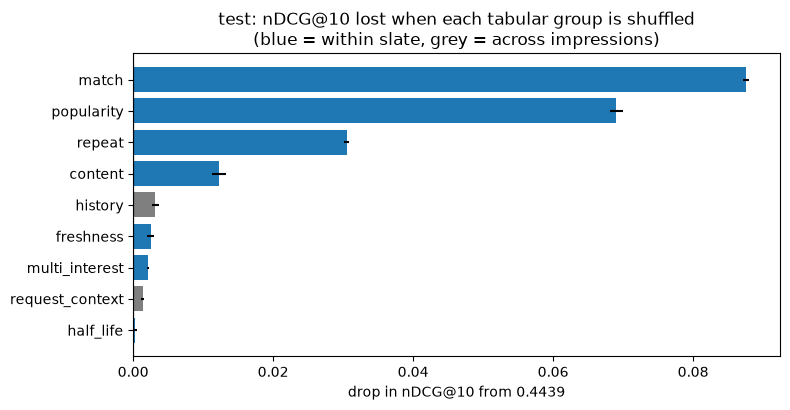

For scale: the RR4 lead over the popularity rule is 0.0883 nDCG@10.


In [122]:
def impression_level(columns):
    """True when every column has a single value inside every impression."""
    values = importance_frame[columns]
    first = values.iloc[FIRST_ROW[ROW_IMPRESSION]].to_numpy()
    current = values.to_numpy()
    return bool(np.all((current == first) | (np.isnan(current) & np.isnan(first))))


def permute(columns, level, rng):
    """Raw features with one group's columns shuffled within slates or across impressions."""
    values = importance_frame[columns].to_numpy()
    if level == "impression":
        donor = rng.permutation(len(FIRST_ROW))
        shuffled = values[FIRST_ROW[donor]][ROW_IMPRESSION]
    else:
        # Rows are sorted by impression, so ordering by (impression, random key) permutes each slate in place
        shuffled = values[np.lexsort((rng.random(len(values)), ROW_IMPRESSION))]
    features = importance_frame[FEATURES].copy()
    features[columns] = shuffled
    return features


permutation_rows = []
started = time.monotonic()
for group, columns in FEATURE_GROUPS.items():
    level = "impression" if impression_level(columns) else "within slate"
    for repeat in range(PERMUTATION_REPEATS):
        rng = np.random.default_rng(SEED + repeat)
        quality = ranking_quality(score_tabular(permute(columns, level, rng), importance_context))
        permutation_rows.append({"group": group, "features": len(columns), "shuffle": level, "repeat": repeat, **quality})
    print(f"{group:<16} {level:<13} done ({time.monotonic() - started:.0f}s)")

permutation_runs = pl.DataFrame(permutation_rows).with_columns(
    (BASE_QUALITY["ndcg_at_10"] - pl.col("ndcg_at_10")).alias("ndcg_drop"),
    (BASE_QUALITY["mrr"] - pl.col("mrr")).alias("mrr_drop"),
)
permutation_importance = (
    permutation_runs.group_by("group", "features", "shuffle", maintain_order=True)
    .agg(
        pl.col("ndcg_drop").mean().alias("ndcg_at_10_drop"),
        pl.col("ndcg_drop").std().alias("ndcg_at_10_drop_std"),
        pl.col("mrr_drop").mean().alias("mrr_drop"),
        pl.col("mrr_drop").std().alias("mrr_drop_std"),
    )
    .with_columns(
        (100 * pl.col("ndcg_at_10_drop") / BASE_QUALITY["ndcg_at_10"]).alias("ndcg_at_10_drop_pct"),
        (BASE_QUALITY["ndcg_at_10"] - pl.col("ndcg_at_10_drop")).alias("ndcg_at_10_permuted"),
        (pl.col("ndcg_at_10_drop") / pl.col("features")).alias("ndcg_at_10_drop_per_feature"),
    )
    .sort("ndcg_at_10_drop", descending=True)
)
print(f"{TARGET_SPLIT.upper()}: drop when a feature group is shuffled (RR4 nDCG@10 {BASE_QUALITY['ndcg_at_10']:.4f})")
display(permutation_importance)

popularity_reference = overall.filter(pl.col("model") == POPULARITY_MODEL)["ndcg_at_10"][0]
plot_frame = permutation_importance.sort("ndcg_at_10_drop")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(
    plot_frame["group"],
    plot_frame["ndcg_at_10_drop"],
    xerr=plot_frame["ndcg_at_10_drop_std"].fill_null(0),
    color=["tab:gray" if s == "impression" else "tab:blue" for s in plot_frame["shuffle"]],
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    title=f"{TARGET_SPLIT}: nDCG@10 lost when each tabular group is shuffled\n(blue = within slate, grey = across impressions)",
    xlabel=f"drop in nDCG@10 from {BASE_QUALITY['ndcg_at_10']:.4f}",
)
plt.tight_layout()
plt.show()
print(f"For scale: the RR4 lead over the popularity rule is {BASE_QUALITY['ndcg_at_10'] - popularity_reference:.4f} nDCG@10.")

## 8.3 Single-Feature Permutation Importance

Each of the tabular features is now shuffled **on its own**, with the same rules as section 8.2
(within the slate, or across impressions for user-level features) and the same seeds. This shows
which features inside a group do the work, and removes the group-size effect.

Single-feature drops are not expected to add up to the group drop:

- **Overlapping features** (for example `text_cosine`, `entity_cosine` and `long_term_cosine` all
  measure similarity) can stand in for each other. Shuffling one leaves the others intact, so each
  looks unimportant on its own while the group as a whole matters. Then the group drop is larger
  than the sum of the single drops.
- **Complementary features**, which only help in combination, push the other way: shuffling any one
  of them already breaks the combination, so the single drops add up to more than the group drop.

`group_drop / sum_of_single_drops` in the second table summarises this: well above 1 means the
group's features largely back each other up.

content           9 features done (270s)
history           9 features done (450s)
match            11 features done (560s)
repeat            6 features done (620s)
popularity        4 features done (659s)
freshness         2 features done (679s)
multi_interest    4 features done (717s)
half_life         3 features done (747s)
request_context   2 features done (765s)
TEST: drop when one feature is shuffled (top 20 of 50)


feature,group,shuffle,ndcg_at_10_drop,ndcg_at_10_drop_std,mrr_drop,ndcg_at_10_drop_pct
str,str,str,f64,f64,f64,f64
"""smoothed_prior_article_ctr""","""popularity""","""within slate""",0.038558,0.000134,0.042277,8.685492
"""log_prior_article_clicks""","""popularity""","""within slate""",0.02753,0.000597,0.02697,6.201396
"""subcategory_affinity""","""match""","""within slate""",0.025569,0.000625,0.027916,5.759623
"""log_prior_article_exposures""","""popularity""","""within slate""",0.02399,0.000492,0.023958,5.403828
"""no_prior_pair_exposure""","""repeat""","""within slate""",0.021054,0.00007,0.020122,4.7426
…,…,…,…,…,…,…
"""log_prior_exposure_count""","""repeat""","""within slate""",0.002071,0.000019,0.002282,0.466578
"""subcategory_code""","""content""","""within slate""",0.002027,0.000548,0.002346,0.456665
"""hours_since_previous_impressio…","""request_context""","""impression""",0.001471,0.00011,0.001742,0.331284


Group drop compared with the sum of its single-feature drops


group,features,sum_of_single_drops,largest_single_drop,top_feature,group_drop,group_drop / sum_of_single_drops
str,u32,f64,f64,str,f64,f64
"""match""",11,0.065257,0.025569,"""subcategory_affinity""",0.0876,1.342378
"""popularity""",4,0.090375,0.038558,"""smoothed_prior_article_ctr""",0.069021,0.763723
"""repeat""",6,0.032838,0.021054,"""no_prior_pair_exposure""",0.030506,0.928981
"""content""",9,0.008088,0.003926,"""category_code""",0.012268,1.516859
"""history""",9,0.002209,0.001415,"""log_history_length""",0.003179,1.439131
"""freshness""",2,0.002629,0.002515,"""article_age_hours""",0.002509,0.954275
"""multi_interest""",4,0.002107,0.002107,"""multi_interest_match_score""",0.002107,1.0
"""request_context""",2,0.001454,0.001471,"""hours_since_previous_impressio…",0.001378,0.947661
"""half_life""",3,0.000288,0.000154,"""stale_after_grace""",0.000311,1.078365


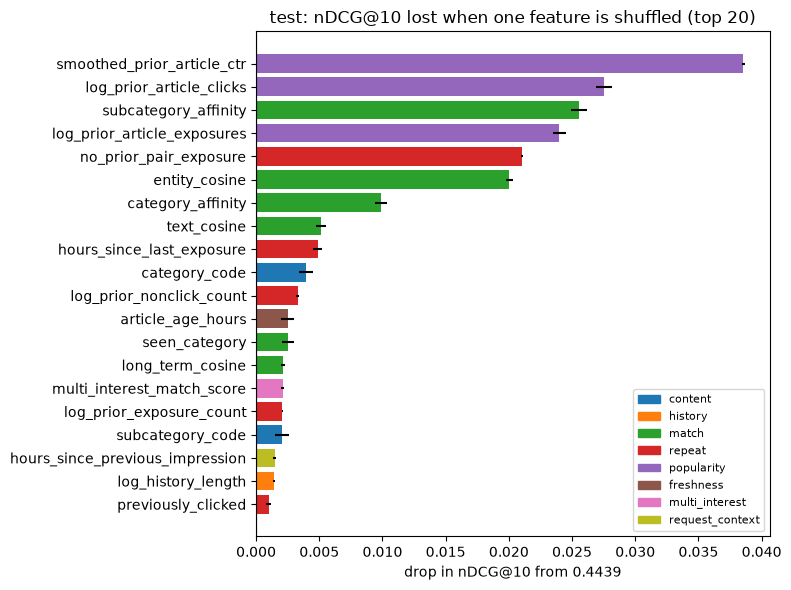

In [123]:
single_rows = []
started = time.monotonic()
for group, columns in FEATURE_GROUPS.items():
    level = "impression" if impression_level(columns) else "within slate"
    for feature in columns:
        for repeat in range(PERMUTATION_REPEATS):
            rng = np.random.default_rng(SEED + repeat)
            quality = ranking_quality(score_tabular(permute([feature], level, rng), importance_context))
            single_rows.append({"feature": feature, "group": group, "shuffle": level, "repeat": repeat, **quality})
    print(f"{group:<16} {len(columns):>2} features done ({time.monotonic() - started:.0f}s)")

single_feature_importance = (
    pl.DataFrame(single_rows)
    .with_columns(
        (BASE_QUALITY["ndcg_at_10"] - pl.col("ndcg_at_10")).alias("ndcg_drop"),
        (BASE_QUALITY["mrr"] - pl.col("mrr")).alias("mrr_drop"),
    )
    .group_by("feature", "group", "shuffle", maintain_order=True)
    .agg(
        pl.col("ndcg_drop").mean().alias("ndcg_at_10_drop"),
        pl.col("ndcg_drop").std().alias("ndcg_at_10_drop_std"),
        pl.col("mrr_drop").mean().alias("mrr_drop"),
    )
    .with_columns((100 * pl.col("ndcg_at_10_drop") / BASE_QUALITY["ndcg_at_10"]).alias("ndcg_at_10_drop_pct"))
    .sort("ndcg_at_10_drop", descending=True)
)
print(f"{TARGET_SPLIT.upper()}: drop when one feature is shuffled (top 20 of {single_feature_importance.height})")
display(single_feature_importance.head(20))

print("Group drop compared with the sum of its single-feature drops")
display(
    single_feature_importance.group_by("group")
    .agg(
        pl.len().alias("features"),
        pl.col("ndcg_at_10_drop").sum().alias("sum_of_single_drops"),
        pl.col("ndcg_at_10_drop").max().alias("largest_single_drop"),
        pl.col("feature").sort_by("ndcg_at_10_drop", descending=True).first().alias("top_feature"),
    )
    .join(permutation_importance.select("group", pl.col("ndcg_at_10_drop").alias("group_drop")), on="group")
    .with_columns((pl.col("group_drop") / pl.col("sum_of_single_drops")).alias("group_drop / sum_of_single_drops"))
    .sort("group_drop", descending=True)
)

TOP_FEATURES = 20
group_names = list(FEATURE_GROUPS)
group_colours = {g: plt.cm.tab10(i) for i, g in enumerate(group_names)}
plot_frame = single_feature_importance.head(TOP_FEATURES).reverse()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(
    plot_frame["feature"],
    plot_frame["ndcg_at_10_drop"],
    xerr=plot_frame["ndcg_at_10_drop_std"].fill_null(0),
    color=[group_colours[g] for g in plot_frame["group"]],
)
ax.axvline(0, color="black", linewidth=0.8)
shown_groups = [g for g in group_names if g in set(plot_frame["group"])]
ax.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=group_colours[g]) for g in shown_groups],
    labels=shown_groups,
    loc="lower right",
    fontsize=8,
)
ax.set(
    title=f"{TARGET_SPLIT}: nDCG@10 lost when one feature is shuffled (top {TOP_FEATURES})",
    xlabel=f"drop in nDCG@10 from {BASE_QUALITY['ndcg_at_10']:.4f}",
)
plt.tight_layout()
plt.show()

## 8.4 SHAP Values for the Tabular Inputs

`GradientExplainer` (expected gradients) explains the RR4 logit of every candidate in
`SHAP_IMPRESSIONS` random test impressions, against `SHAP_BACKGROUND_ROWS` random test rows. Both
the tabular inputs and the cached news/user vectors are inputs to the explainer, and only the
tabular attributions are reported. The one-hot columns of `category_code` and `subcategory_code`
are summed back into one value per feature.

- **`mean_abs_shap`**: average size of a feature's contribution to the score.
- **`mean_abs_within_slate_shap`**: the same after subtracting each slate's mean contribution.
  Only this part can change the order of a slate, so it is the SHAP measure to compare with
  sections 8.2 and 8.3. Impression-level features score near zero here.

The beeswarm plot shows the direction for the numeric features: each dot is one candidate, its
colour is the feature's standardised value (red = high) and its position is the push on the score.

SHAP for 4,241 candidates in 100 impressions (30s)
TEST: top 15 tabular features by within-slate SHAP


feature,group,mean_abs_shap,mean_abs_within_slate_shap,mean_shap
str,str,f64,f64,f64
"""log_prior_article_clicks""","""popularity""",0.335185,0.313524,-0.019353
"""log_prior_article_exposures""","""popularity""",0.271757,0.258809,0.017449
"""smoothed_prior_article_ctr""","""popularity""",0.24258,0.227897,-0.002958
"""subcategory_affinity""","""match""",0.188599,0.180334,0.016484
"""entity_cosine""","""match""",0.181622,0.173494,0.006109
…,…,…,…,…
"""log_prior_nonclick_count""","""repeat""",0.100056,0.064669,0.01688
"""text_cosine""","""match""",0.065642,0.061691,-0.007461
"""log_prior_exposure_count""","""repeat""",0.085131,0.055698,0.01305


By group (sum over the group's features)


group,mean_abs_shap,mean_abs_within_slate_shap
str,f64,f64
"""popularity""",0.856223,0.80721
"""match""",0.731829,0.664131
"""repeat""",0.49965,0.318877
"""content""",0.310767,0.30299
"""history""",0.151262,0.099913
"""freshness""",0.057112,0.055425
"""request_context""",0.078594,0.035279
"""multi_interest""",0.031891,0.027204
"""half_life""",0.016739,0.017576


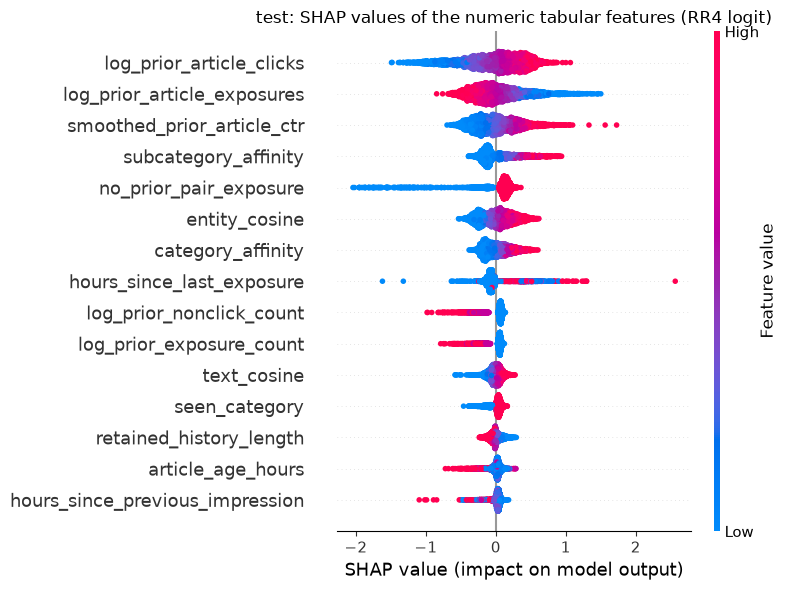

In [129]:
import warnings

warnings.filterwarnings("ignore", message="The NumPy global RNG was seeded")
warnings.filterwarnings("ignore", message="IProgress not found")

try:
    import shap
except ImportError:  # preinstalled on Colab; installed here for local runs
    import subprocess

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap
import copy


class TabularScorer(nn.Module):
    """RR4's final MLP as a function of (tabular inputs, cached news and user vectors)."""

    def __init__(self, scorer):
        super().__init__()
        self.scorer = scorer

    def forward(self, tabular, context):
        return self.scorer(torch.cat([tabular, context], dim=1))


rng = np.random.default_rng(SEED)
shap_impressions = rng.choice(len(FIRST_ROW), size=min(SHAP_IMPRESSIONS, len(FIRST_ROW)), replace=False)
shap_rows = np.flatnonzero(np.isin(ROW_IMPRESSION, shap_impressions))
background_rows = rng.choice(len(importance_frame), size=SHAP_BACKGROUND_ROWS, replace=False)


def tabular_inputs(rows):
    return torch.from_numpy(
        preprocessor.transform(importance_frame.iloc[rows][FEATURES]).astype(np.float32, copy=False)
    )


explained_tabular = tabular_inputs(shap_rows)
explainer_model = TabularScorer(copy.deepcopy(model.scorer).cpu()).eval()
explainer = shap.GradientExplainer(
    explainer_model, [tabular_inputs(background_rows), importance_context[background_rows]]
)
started = time.monotonic()
shap_output = explainer.shap_values([explained_tabular, importance_context[shap_rows]])
tabular_shap = np.asarray(shap_output[0]).reshape(len(shap_rows), -1)  # [rows, tabular columns]
print(f"SHAP for {len(shap_rows):,} candidates in {len(shap_impressions)} impressions ({time.monotonic() - started:.0f}s)")

# One SHAP value per original feature: the one-hot columns of a categorical feature are summed
column_names = preprocessor.get_feature_names_out()
feature_columns = {
    name: [
        i
        for i, column in enumerate(column_names)
        if column == f"numeric__{name}" or column.startswith(f"categorical__{name}_")
    ]
    for name in FEATURES
}
feature_shap = np.column_stack([tabular_shap[:, feature_columns[name]].sum(axis=1) for name in FEATURES])
slate_mean = pd.DataFrame(feature_shap).groupby(ROW_IMPRESSION[shap_rows]).transform("mean").to_numpy()
within_slate_shap = feature_shap - slate_mean

shap_importance = (
    pl.DataFrame(
        {
            "feature": FEATURES,
            "group": [FEATURE_TO_GROUP[name] for name in FEATURES],
            "mean_abs_shap": np.abs(feature_shap).mean(axis=0),
            "mean_abs_within_slate_shap": np.abs(within_slate_shap).mean(axis=0),
            "mean_shap": feature_shap.mean(axis=0),
        }
    )
    .sort("mean_abs_within_slate_shap", descending=True)
)
print(f"{TARGET_SPLIT.upper()}: top 15 tabular features by within-slate SHAP")
display(shap_importance.head(15))
print("By group (sum over the group's features)")
display(
    shap_importance.group_by("group")
    .agg(pl.col("mean_abs_shap").sum(), pl.col("mean_abs_within_slate_shap").sum())
    .sort("mean_abs_within_slate_shap", descending=True)
)

numeric_index = [FEATURES.index(name) for name in NUMERIC]
shap.summary_plot(
    feature_shap[:, numeric_index],
    features=explained_tabular[:, [feature_columns[name][0] for name in NUMERIC]].numpy(),
    feature_names=NUMERIC,
    max_display=15,
    show=False,
    plot_size=(8, 6),
)
plt.title(f"{TARGET_SPLIT}: SHAP values of the numeric tabular features (RR4 logit)")
plt.tight_layout()
plt.show()

## 8.5 Save the Importance Tables

- `RESULTS/rr_only_feature_permutation_<split>.csv`: one row per feature group
- `RESULTS/rr_only_feature_permutation_single_<split>.csv`: one row per tabular feature
- `RESULTS/rr_only_feature_shap_<split>.csv`: one row per tabular feature

In [ ]:
permutation_path = RESULTS / f"rr_only_feature_permutation_{TARGET_SPLIT}.csv"
single_path = RESULTS / f"rr_only_feature_permutation_single_{TARGET_SPLIT}.csv"
shap_path = RESULTS / f"rr_only_feature_shap_{TARGET_SPLIT}.csv"
permutation_importance.with_columns(
    pl.lit(BASE_QUALITY["ndcg_at_10"]).alias("base_ndcg_at_10"),
    pl.lit(PERMUTATION_REPEATS).alias("repeats"),
).write_csv(permutation_path)
single_feature_importance.with_columns(pl.lit(PERMUTATION_REPEATS).alias("repeats")).write_csv(single_path)
shap_importance.write_csv(shap_path)
for path in (permutation_path, single_path, shap_path):
    print("Saved:", path)

Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_feature_permutation_test.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_feature_permutation_single_test.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_feature_shap_test.csv


# 9. Model Diagnostics

Five checks on the trained RR4 reranker, compared with the popularity baseline:

1. **Training convergence** (9.1): how did the training and validation loss behave, and where did
   early stopping on validation nDCG@10 cut in?
2. **Generalisation** (9.2): how much do both models lose between the validation day and the test
   day? A model tuned too closely to validation would lose more than the untrained popularity rule.
3. **Where RR4 wins and loses** (9.3): slate-by-slate wins, ties and losses, and nDCG@10 by slate
   size.
4. **New and older articles** (9.4): where each model ranks the clicked article, by how much
   history the article has and by its age.
5. **Failure analysis** (9.5): what the clicks RR4 ranks outside the top 10 have in common,
   including articles the user had already been shown.

All rankings use the saved score files from section 5 with the evaluator's tie-break (score
descending, then `news_code` ascending). Section 9.0 checks that the per-slate nDCG@10 computed
here reproduces the evaluator's overall value.

## 9.0 Per-Slate Ranks and nDCG@10

One row per (impression, shown article), with each model's rank of the article within its slate,
and one row per impression with each model's nDCG@10 (binary gains, impressions with a click).

In [130]:
DIAGNOSTIC_FEATURES = [
    "no_prior_article_exposure",
    "log_prior_article_exposures",
    "article_age_hours",
    "no_prior_pair_exposure",
    "smoothed_prior_article_ctr",
    "entity_cosine",
    "subcategory_affinity",
]
SHORT = {RR4_MODEL: "rr4", POPULARITY_MODEL: "pop", CONTENT_MODEL: "content"}


def ranked_slates(split, score_files):
    """Labels, diagnostic features and each model's within-slate rank for every logged pair."""
    keys = ["impression_uid", "news_code"]
    frame = (
        pl.scan_parquet(RUN / f"labels_{split}" / "*.parquet")
        .select(*keys, "clicked")
        .join(
            pl.scan_parquet(RUN / f"ranking_features_{split}" / "*.parquet").select(
                *keys, *DIAGNOSTIC_FEATURES
            ),
            on=keys,
        )
    )
    for model_name, path in score_files.items():
        frame = frame.join(
            pl.scan_parquet(path).select(*keys, pl.col("score").alias(f"score_{SHORT[model_name]}")),
            on=keys,
        )
    frame = frame.collect()
    return frame.with_columns(
        *[
            pl.struct(-pl.col(f"score_{SHORT[m]}"), pl.col("news_code"))
            .rank("ordinal")
            .over("impression_uid")
            .alias(f"rank_{SHORT[m]}")
            for m in score_files
        ],
        pl.len().over("impression_uid").alias("slate_size"),
    )


def slate_ndcg(frame, models, k=10):
    """nDCG@k per impression (binary gains) for each model; impressions without a click are dropped."""
    discount = lambda rank: 1 / (rank + 1).log(2)
    per_impression = frame.group_by("impression_uid").agg(
        pl.first("slate_size"),
        pl.col("clicked").sum().alias("clicks"),
        *[
            pl.when((pl.col("clicked") == 1) & (pl.col(f"rank_{m}") <= k))
            .then(discount(pl.col(f"rank_{m}")))
            .otherwise(0.0)
            .sum()
            .alias(f"dcg_{m}")
            for m in models
        ],
    ).filter(pl.col("clicks") > 0)
    ideal = {n: float(sum(1 / np.log2(i + 2) for i in range(min(n, k)))) for n in range(1, int(per_impression["clicks"].max()) + 1)}
    per_impression = per_impression.with_columns(
        pl.col("clicks").cast(pl.Int64).replace_strict(ideal, return_dtype=pl.Float64).alias("idcg")
    )
    return per_impression.with_columns(
        *[(pl.col(f"dcg_{m}") / pl.col("idcg")).alias(f"ndcg_{m}") for m in models]
    ).drop("idcg", *[f"dcg_{m}" for m in models])


diagnostic_rows = ranked_slates(TARGET_SPLIT, {m: score_path(m) for m in MODEL_NAMES})
diagnostic_slates = slate_ndcg(diagnostic_rows, list(SHORT.values()))
check = {
    SHORT[m]: (diagnostic_slates[f"ndcg_{SHORT[m]}"].mean(), overall.filter(pl.col("model") == m)["ndcg_at_10"][0])
    for m in MODEL_NAMES
}
for name, (here, evaluator_value) in check.items():
    print(f"{name:<8} per-slate mean nDCG@10 {here:.4f}  (evaluator: {evaluator_value:.4f})")
    if abs(here - evaluator_value) > 1e-6:
        raise ValueError("Per-slate nDCG@10 does not reproduce the evaluator")
print(f"{diagnostic_rows.height:,} logged pairs, {diagnostic_slates.height:,} impressions with a click")

pop      per-slate mean nDCG@10 0.3557  (evaluator: 0.3557)
content  per-slate mean nDCG@10 0.3056  (evaluator: 0.3056)
rr4      per-slate mean nDCG@10 0.4439  (evaluator: 0.4439)
1,222,429 logged pairs, 30,270 impressions with a click


## 9.1 Training Convergence

Training loss and validation loss per epoch (left), and validation nDCG@10, the early-stopping
metric (right), from the training run or the checkpoint's saved history. Training loss is the mean
over the epoch's capped training slates with dropout on. Validation loss is measured after each
epoch on the full validation-day slates in evaluation mode. Validation slates are longer and
uncapped, and a listwise loss grows with the number of non-clicked candidates, so compare the
**trend** of the two curves rather than their level. Because the validation day chose the epoch,
the validation score of the final model is slightly optimistic; the test day (section 5) is the
unbiased estimate.

,epoch,loss,validation_loss,validation_ndcg_at_10,minutes
0,1,1.6560,1.7444,0.4633,1.1725
1,2,1.6226,1.7393,0.4645,1.4069
2,3,1.6085,1.7297,0.4664,1.7990
3,4,1.5970,1.7309,0.4663,1.8467
4,5,1.5892,1.7276,0.4674,1.7421
5,6,1.5804,1.7338,0.4670,1.8231
6,7,1.5729,1.7239,0.4667,1.7967
7,8,1.5653,1.7311,0.4642,2.0716


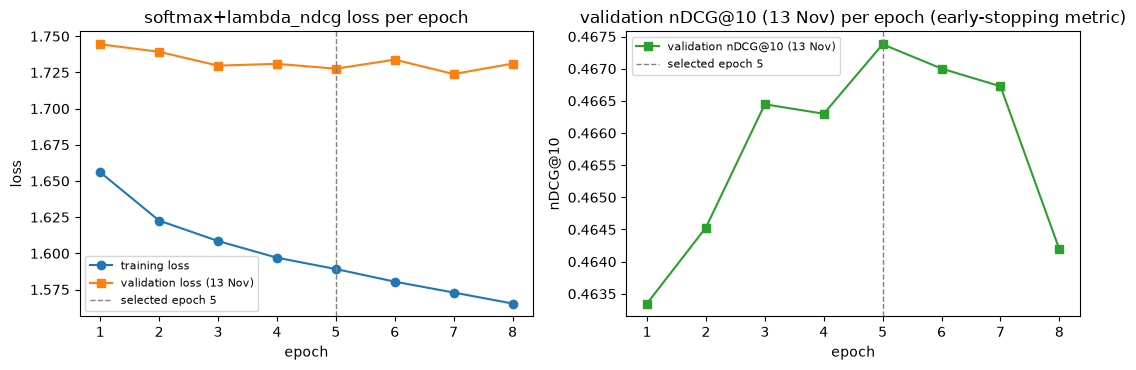

Best epoch 5 (validation nDCG@10 (13 Nov) 0.4674); 3 later epochs within 0.0032 of it


In [125]:
training_history = pd.DataFrame(model.history)
if training_history.empty:
    print("No training history was saved with this checkpoint")
else:
    display(training_history.round(4))
    # Older checkpoints stopped on a training holdout and have no validation curve
    ndcg_column = "validation_ndcg_at_10" if "validation_ndcg_at_10" in training_history else "holdout_ndcg_at_10"
    ndcg_label = "validation nDCG@10 (13 Nov)" if ndcg_column.startswith("validation") else "holdout nDCG@10"
    fig, (ax_loss, ax_ndcg) = plt.subplots(1, 2, figsize=(11, 3.8))
    ax_loss.plot(training_history["epoch"], training_history["loss"], marker="o", label="training loss")
    if "validation_loss" in training_history:
        ax_loss.plot(
            training_history["epoch"], training_history["validation_loss"], marker="s", label="validation loss (13 Nov)"
        )
    ax_loss.set(title=f"{LOSS_NAME} loss per epoch", xlabel="epoch", ylabel="loss")
    ax_ndcg.plot(training_history["epoch"], training_history[ndcg_column], marker="s", color="tab:green", label=ndcg_label)
    ax_ndcg.set(title=f"{ndcg_label} per epoch (early-stopping metric)", xlabel="epoch", ylabel="nDCG@10")
    for ax in (ax_loss, ax_ndcg):
        ax.axvline(model.best_epoch, color="grey", linestyle="--", linewidth=1, label=f"selected epoch {model.best_epoch}")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    if "validation_loss" not in training_history:
        print("This checkpoint was trained before validation loss was recorded; retrain to plot it")
    after_best = training_history[training_history["epoch"] > model.best_epoch]
    print(
        f"Best epoch {model.best_epoch} ({ndcg_label} {model.best_validation_ndcg:.4f}); "
        f"{len(after_best)} later epochs within {model.best_validation_ndcg - after_best[ndcg_column].min():.4f} of it"
        if len(after_best)
        else f"Best epoch {model.best_epoch}: the last epoch trained"
    )


## 9.2 Validation-to-Test Gap

RR4 and the popularity rule are scored on the other evaluation split as well, so both days are
compared with the same code. Every modelling choice was made on validation, so a model fitted too
closely to it would lose more on test than the untrained popularity rule does. A steady lead over
popularity on both days means the drop comes from the day, not from the model.

In [131]:
OTHER_SPLIT = "validation" if TARGET_SPLIT == "test" else "test"
gap_rows = [
    {"split": TARGET_SPLIT, "model": m, "ndcg_at_10": overall.filter(pl.col("model") == m)["ndcg_at_10"][0]}
    for m in (POPULARITY_MODEL, RR4_MODEL)
]
other_ready = all((RUN / f"{kind}_{OTHER_SPLIT}").exists() for kind in ("ranking_features", "labels", "request_profiles"))
if not other_ready:
    print(f"Skipped: the {OTHER_SPLIT} features, labels or profiles are not in the data folder")
else:
    started = time.monotonic()
    other_evaluator = RerankingEvaluator(split=OTHER_SPLIT, feature_run=RUN)
    other_scorers = {
        POPULARITY_MODEL: (popularity_score, POPULARITY_COLUMNS),
        RR4_MODEL: (rr4_predictor(model, load_profiles(OTHER_SPLIT)), FEATURES),
    }
    for m, (predict, columns) in other_scorers.items():
        path = SCORE_DIR / f"{m}_{OTHER_SPLIT}_scores.parquet"
        write_scores(predict, split=OTHER_SPLIT, feature_run=RUN, output_path=path, columns=columns)
        result = other_evaluator.evaluate(path, model_name=m, k_values=(10,), metric_names=("ndcg",))
        gap_rows.append({"split": OTHER_SPLIT, "model": m, "ndcg_at_10": result["ndcg_at_10"][0]})
    print(f"Scored {OTHER_SPLIT} ({time.monotonic() - started:.0f}s)")

    generalisation = (
        pl.DataFrame(gap_rows)
        .with_columns(pl.col("model").replace_strict(MODEL_LABELS))
        .pivot(on="split", index="model", values="ndcg_at_10")
        .select("model", "validation", "test")
        .with_columns(
            (pl.col("test") - pl.col("validation")).alias("change"),
            (100 * (pl.col("test") / pl.col("validation") - 1)).alias("change_pct"),
        )
    )
    display(generalisation)
    lead = generalisation.select(pl.col("validation", "test").diff().last())
    print(
        f"RR4 lead over popularity: validation {lead['validation'][0]:+.4f}, test {lead['test'][0]:+.4f}"
    )

Scored validation (24s)


model,validation,test,change,change_pct
str,f64,f64,f64,f64
"""Popularity (rule)""",0.37621,0.355655,-0.020555,-5.463645
"""RR4 attention reranker""",0.467379,0.44394,-0.023439,-5.014993


RR4 lead over popularity: validation +0.0912, test +0.0883


## 9.3 Where RR4 Wins and Loses

**Slate by slate**: the share of impressions where RR4's nDCG@10 is higher than, equal to or lower
than each baseline's. **By slate size**: longer slates are harder because more articles compete for
the top 10.

TEST: share of impressions by nDCG@10 comparison


compared_with,rr4_better,tie,rr4_worse
str,f64,f64,f64
"""Popularity (rule)""",0.444764,0.32263,0.232607
"""Content similarity (rule)""",0.519227,0.272844,0.207929


TEST: nDCG@10 by slate size


slate_size_bin,impressions,popularity_ndcg_at_10,rr4_ndcg_at_10,rr4_better_share,rr4_gain_pct
str,u32,f64,f64,f64,f64
"""2-10""",6450,0.709582,0.75479,0.328682,6.371069
"""11-25""",8138,0.376175,0.492086,0.542885,30.81288
"""26-50""",7300,0.237882,0.357163,0.496438,50.142979
"""51-100""",5608,0.181832,0.25781,0.41316,41.784898
"""101+""",2774,0.133858,0.184569,0.354722,37.884281


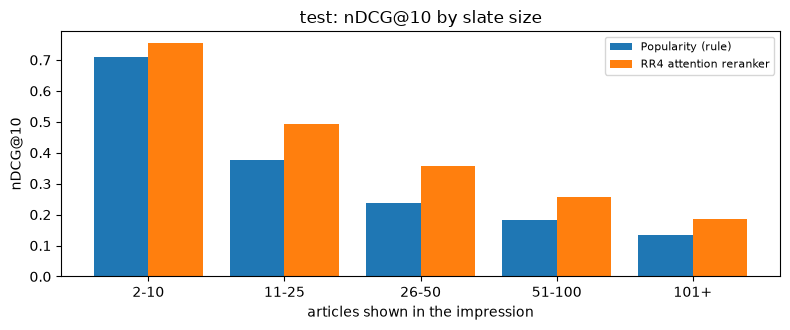

In [132]:
win_loss = pl.DataFrame(
    [
        {
            "compared_with": MODEL_LABELS[m],
            "rr4_better": ((diagnostic_slates["ndcg_rr4"] - diagnostic_slates[f"ndcg_{SHORT[m]}"]) > 1e-9).mean(),
            "tie": ((diagnostic_slates["ndcg_rr4"] - diagnostic_slates[f"ndcg_{SHORT[m]}"]).abs() <= 1e-9).mean(),
            "rr4_worse": ((diagnostic_slates["ndcg_rr4"] - diagnostic_slates[f"ndcg_{SHORT[m]}"]) < -1e-9).mean(),
        }
        for m in (POPULARITY_MODEL, CONTENT_MODEL)
    ]
)
print(f"{TARGET_SPLIT.upper()}: share of impressions by nDCG@10 comparison")
display(win_loss)

SLATE_SIZE_BINS = [(2, 10), (11, 25), (26, 50), (51, 100), (101, None)]
size_bin = pl.lit(None, dtype=pl.Utf8)
for low, high in reversed(SLATE_SIZE_BINS):
    label = f"{low}+" if high is None else f"{low}-{high}"
    condition = pl.col("slate_size") >= low if high is None else pl.col("slate_size").is_between(low, high)
    size_bin = pl.when(condition).then(pl.lit(label)).otherwise(size_bin)
SIZE_ORDER = [f"{low}+" if high is None else f"{low}-{high}" for low, high in SLATE_SIZE_BINS]

by_slate_size = (
    diagnostic_slates.with_columns(size_bin.alias("slate_size_bin"))
    .group_by("slate_size_bin")
    .agg(
        pl.len().alias("impressions"),
        pl.col("ndcg_pop").mean().alias("popularity_ndcg_at_10"),
        pl.col("ndcg_rr4").mean().alias("rr4_ndcg_at_10"),
        ((pl.col("ndcg_rr4") - pl.col("ndcg_pop")) > 1e-9).mean().alias("rr4_better_share"),
    )
    .with_columns((100 * (pl.col("rr4_ndcg_at_10") / pl.col("popularity_ndcg_at_10") - 1)).alias("rr4_gain_pct"))
    .sort(pl.col("slate_size_bin").replace_strict({b: i for i, b in enumerate(SIZE_ORDER)}))
)
print(f"{TARGET_SPLIT.upper()}: nDCG@10 by slate size")
display(by_slate_size)

fig, ax = plt.subplots(figsize=(8, 3.4))
positions = np.arange(by_slate_size.height)
ax.bar(positions - 0.2, by_slate_size["popularity_ndcg_at_10"], 0.4, label=MODEL_LABELS[POPULARITY_MODEL])
ax.bar(positions + 0.2, by_slate_size["rr4_ndcg_at_10"], 0.4, label=MODEL_LABELS[RR4_MODEL])
ax.set_xticks(positions, by_slate_size["slate_size_bin"])
ax.set(title=f"{TARGET_SPLIT}: nDCG@10 by slate size", xlabel="articles shown in the impression", ylabel="nDCG@10")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 9.4 New and Older Articles

For every clicked article: the share that each model places in the top 10 of its slate, and its
mean relative rank (0 = top of the slate, 1 = bottom). Clicks are grouped by how many times the
article had been shown before the impression (all users, causal) and by the article's age.
Popularity cannot rank an article with no history, so this shows how much RR4 relies on it.

In [ ]:
clicks = diagnostic_rows.filter(pl.col("clicked") == 1).with_columns(
    pl.when(pl.col("no_prior_article_exposure") == 1)
    .then(pl.lit("never shown before"))
    .when(pl.col("log_prior_article_exposures") < np.log1p(100))
    .then(pl.lit("1-99 prior impressions"))
    .otherwise(pl.lit("100+ prior impressions"))
    .alias("article_history"),
    pl.when(pl.col("article_age_hours") < 6)
    .then(pl.lit("< 6 hours"))
    .when(pl.col("article_age_hours") < 24)
    .then(pl.lit("6-24 hours"))
    .when(pl.col("article_age_hours") < 72)
    .then(pl.lit("1-3 days"))
    .otherwise(pl.lit("3+ days"))
    .alias("article_age"),
    pl.when(pl.col("no_prior_pair_exposure") == 1)
    .then(pl.lit("first time shown to this user"))
    .otherwise(pl.lit("shown to this user before"))
    .alias("user_exposure"),
    *[
        ((pl.col(f"rank_{m}") - 1) / (pl.col("slate_size") - 1).clip(lower_bound=1)).alias(f"relative_rank_{m}")
        for m in ("rr4", "pop")
    ],
)


def click_placement(by, order):
    return (
        clicks.group_by(by)
        .agg(
            pl.len().alias("clicks"),
            (pl.col("rank_pop") <= 10).mean().alias("popularity_top10"),
            (pl.col("rank_rr4") <= 10).mean().alias("rr4_top10"),
            pl.col("relative_rank_pop").mean().alias("popularity_mean_relative_rank"),
            pl.col("relative_rank_rr4").mean().alias("rr4_mean_relative_rank"),
        )
        .sort(pl.col(by).replace_strict({value: i for i, value in enumerate(order)}))
    )


by_article_history = click_placement(
    "article_history", ["never shown before", "1-99 prior impressions", "100+ prior impressions"]
)
by_article_age = click_placement("article_age", ["< 6 hours", "6-24 hours", "1-3 days", "3+ days"])
print(f"{TARGET_SPLIT.upper()}: clicked articles by how often the article had been shown before")
display(by_article_history)
print(f"{TARGET_SPLIT.upper()}: clicked articles by article age")
display(by_article_age)

TEST: clicked articles by how often the article had been shown before


article_history,clicks,popularity_top10,rr4_top10,popularity_mean_relative_rank,rr4_mean_relative_rank
str,u32,f64,f64,f64,f64
"""never shown before""",148,0.074324,0.554054,0.395235,0.201767
"""1-99 prior impressions""",3538,0.363482,0.571792,0.383625,0.240348
"""100+ prior impressions""",43139,0.526554,0.607409,0.348985,0.282932


TEST: clicked articles by article age


article_age,clicks,popularity_top10,rr4_top10,popularity_mean_relative_rank,rr4_mean_relative_rank
str,u32,f64,f64,f64,f64
"""< 6 hours""",8469,0.656512,0.727359,0.271556,0.216158
"""6-24 hours""",29708,0.535142,0.609903,0.350222,0.286539
"""1-3 days""",6371,0.319573,0.487679,0.387323,0.284766
"""3+ days""",2277,0.227492,0.404919,0.570404,0.407651


## 9.5 Failure Analysis

Clicks that RR4 ranks **outside** the top 10 compared with clicks it ranks inside, on slate size,
the article's popularity, its similarity to the user's history, and whether the user had been shown
the article before. The second table isolates clicks on articles the user had already been shown:
RR4 learned that such articles are usually ignored (section 8), which costs it the clicks where the
user does come back to one.

The last line counts slates with tied scores. Ties are ordered by `news_code`, not by the model, so
many ties mean the model cannot tell those candidates apart.

In [ ]:
missed_vs_found = (
    clicks.with_columns(
        pl.when(pl.col("rank_rr4") <= 10).then(pl.lit("found (top 10)")).otherwise(pl.lit("missed (outside top 10)")).alias("rr4_result")
    )
    .group_by("rr4_result")
    .agg(
        pl.len().alias("clicks"),
        pl.col("slate_size").median().alias("median_slate_size"),
        pl.col("smoothed_prior_article_ctr").median().alias("median_prior_ctr"),
        pl.col("entity_cosine").median().alias("median_entity_cosine"),
        pl.col("subcategory_affinity").median().alias("median_subcategory_affinity"),
        (pl.col("no_prior_pair_exposure") == 0).mean().alias("share_shown_to_user_before"),
        (pl.col("no_prior_article_exposure") == 1).mean().alias("share_never_shown_before"),
    )
    .sort("rr4_result", descending=True)
)
print(f"{TARGET_SPLIT.upper()}: clicks RR4 missed vs found")
display(missed_vs_found)

by_user_exposure = click_placement("user_exposure", ["first time shown to this user", "shown to this user before"])
print(f"{TARGET_SPLIT.upper()}: clicks by whether the user had been shown the article before")
display(by_user_exposure)

tied_slates = diagnostic_rows.group_by("impression_uid").agg(
    *[(pl.col(f"score_{s}").n_unique() < pl.len()).alias(s) for s in SHORT.values()]
)
print(
    "Share of slates with at least one tied score: "
    + ", ".join(f"{MODEL_LABELS[m]} {tied_slates[SHORT[m]].mean():.2%}" for m in MODEL_NAMES)
)

TEST: clicks RR4 missed vs found


rr4_result,clicks,median_slate_size,median_prior_ctr,median_entity_cosine,median_subcategory_affinity,share_shown_to_user_before,share_never_shown_before
str,u32,f64,f32,f32,f32,f64,f64
"""missed (outside top 10)""",18517,69.0,0.038742,0.391476,0.0,0.141492,0.003564
"""found (top 10)""",28308,23.0,0.073584,0.464873,0.037037,0.068497,0.002897


TEST: clicks by whether the user had been shown the article before


user_exposure,clicks,popularity_top10,rr4_top10,popularity_mean_relative_rank,rr4_mean_relative_rank
str,u32,f64,f64,f64,f64
"""first time shown to this user""",42266,0.518928,0.623882,0.348477,0.264032
"""shown to this user before""",4559,0.456021,0.425313,0.382081,0.422467


Share of slates with at least one tied score: Popularity (rule) 8.33%, Content similarity (rule) 84.77%, RR4 attention reranker 0.06%


## 9.6 Save the Diagnostic Tables

`RESULTS/rr_only_diagnostics_<split>_<table>.csv` for the slate-size, article-history, article-age,
user-exposure, missed-vs-found and validation-to-test tables, plus the training history.

In [ ]:
diagnostic_tables = {
    "slate_size": by_slate_size,
    "win_loss": win_loss,
    "article_history": by_article_history,
    "article_age": by_article_age,
    "user_exposure": by_user_exposure,
    "missed_vs_found": missed_vs_found,
}
if other_ready:
    diagnostic_tables["generalisation"] = generalisation
if not training_history.empty:
    diagnostic_tables["training_history"] = pl.from_pandas(training_history)
for name, table in diagnostic_tables.items():
    path = RESULTS / f"rr_only_diagnostics_{TARGET_SPLIT}_{name}.csv"
    table.write_csv(path)
    print("Saved:", path)

Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_diagnostics_test_slate_size.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_diagnostics_test_win_loss.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_diagnostics_test_article_history.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_diagnostics_test_article_age.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_diagnostics_test_user_exposure.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_diagnostics_test_missed_vs_found.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_diagnostics_test_generalisation.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/rr_only_diagnostics_test_training_history.csv


# 10. Notes and Limitations

- **Logged slates only.** Each model reorders the articles MIND actually showed, so every
  candidate has a label and non-clicks are real negatives. This isolates ranking quality but is
  easier than the deployed task, where the reranker also faces generated candidates that were
  never shown (see `2_CG_RR_E2E`).
- **Selection happened upstream.** The content rule, and RR4's architecture and loss, were chosen
  on validation in `5_02_Reranking`. This notebook retrains the chosen RR4 configuration on the
  training split and early-stops it on the validation day, so the validation score of the final
  model is slightly optimistic. The test day is never used for training or any choice.
- **Loading vs training.** With `TRAIN_RERANKER = False` the saved model is loaded from the load
  path and never retrained; set it to `True` in the Configure cell to retrain and save to the save
  path.
- **Popularity is a strong baseline on logged slates.** The logging policy already favoured popular
  articles, so the shown slates suit a popularity ranking.
- **Observed CTR lift** is relative to the popularity baseline on the same logged slates. It is an
  offline proxy, not an estimate of online CTR.
- **Cohorts** use the user's click history strictly before each impression, the same causal history
  the models see.
- **Feature importance is not an ablation.** Sections 8.2 and 8.3 explain the trained model; they do
  not retrain it without a group. A group the model leans on may still be replaceable by
  correlated inputs if the model were retrained without it, so confirm a candidate for removal
  by retraining.
